In [1]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 0 · SETUP · Librerías
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Importa pandas y numpy. Nada más: es el arranque del notebook.
## ENTRADA  : —
## SALIDA   : —
## CLAVE    : matplotlib se importa después, dentro de la celda de diagnóstico.
## ──────────────────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np


In [2]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 1 · CARGA · Los 6 insumos desde CSV
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Define CARPETA (origen y destino de todo) y lee los seis archivos
##            de entrada.
## ENTRADA  : REPORTE_INSCRIPCIÓ_FULL (df, 7.413.130 filas) ·
##            MAESTRO_MALLAS_CATALOGO_APERTURADO (df2, 214.490×38) ·
##            PROYECCION_MATRICULA (df3, DESCARTADO D-06) · INDICE_REPROBACION
##            (df4, 131.108) · SCRLEVL (df5) · STVLEVL (df6)
## SALIDA   : df, df2, df3, df4, df5, df6
## CLAVE    : SCRLEVL se lee con dtype=str en subj_code/crse_numb: si pandas
##            infiere entero, '0068' pierde los ceros y el cruce con la regla se
##            rompe.
## ──────────────────────────────────────────────────────────────────────────────
import os

# Carpeta única de entrada y salida: de aquí se leen los insumos y aquí caen los exports.
CARPETA = 'data/raw'

# Cargar archivos
INSCRIPCION       = f'{CARPETA}/REPORTE_INSCRIPCIÓ_FULL_2015_2026_22072026.csv'
MALLAS            = f'{CARPETA}/MAESTRO_MALLAS_CATALOGO_APERTURADO.csv'
PROYECCIÓN_SIMPLE = f'{CARPETA}/PROYECCION_MATRICULA_2026_2031_23072026.CSV'
REPROBACION       = f'{CARPETA}/INDICE_REPROBACION_ASIGNATURA_SEDE_PERIODO.csv'
NIVEL_ASIGNATURA  = f'{CARPETA}/SCRLEVL.csv'      # nivel de la asignatura por periodo efectivo
CATALOGO_NIVEL    = f'{CARPETA}/STVLEVL.csv'      # descriptor del nivel

df  = pd.read_csv(INSCRIPCION, sep=',', encoding='utf-8')
df2 = pd.read_csv(MALLAS, sep=';', encoding='utf-8')
df3 = pd.read_csv(PROYECCIÓN_SIMPLE, sep=',', encoding='utf-8')
df4 = pd.read_csv(REPROBACION, sep=',', encoding='utf-8-sig')
# dtype=str en el nº de curso: preserva los ceros a la izquierda ('0068'), necesarios para el cruce
df5 = pd.read_csv(NIVEL_ASIGNATURA, sep=',', encoding='utf-8',
                  dtype={'scrlevl_subj_code': str, 'scrlevl_crse_numb': str,
                         'scrlevl_eff_term': str, 'scrlevl_levl_code': str})
df6 = pd.read_csv(CATALOGO_NIVEL, sep=',', encoding='utf-8', dtype=str)


<ruta-local>) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv(MALLAS, sep=';', encoding='utf-8')


In [3]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 2 · FORMATOS · Largo de `regla` en df2
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Marca el largo del código de regla. NO aplica zfill(4) a n_curso,
##            decisión verificada empíricamente.
## ENTRADA  : df2
## SALIDA   : df2 + regla_largo, regla_cumple_8
## CLAVE    : zfill(4) ROMPE 2.395 matches de `regla == cod_materia+n_curso`
##            (CEP+100=CEP100 ✓ vs CEP+0100 ✗) y no rescata ninguno. Solo el
##            59,4% de las reglas mide 8 chars, así que se marca en vez de
##            rellenar.
## ──────────────────────────────────────────────────────────────────────────────
# ── Control de formatos en df2 (post-carga) ──────────────────────────────────
# n_curso: NO se aplica zfill(4). Verificado contra los datos: el CSV de origen ya
# trae el valor correcto para el match con `regla` — lo que se ve sin ceros en Excel
# es Excel recortándolos al mostrar, no el dato. Aplicar zfill(4) ROMPE 2.395 matches
# de `regla == cod_materia+n_curso`, sobre todo en materias de 3 caracteres:
#     'CEP' + '100'  = 'CEP100'  == regla CEP100   ✓
#     'CEP' + '0100' = 'CEP0100' != regla CEP100   ✗
# Y tampoco mejora el cruce con la inscripción (9.079 asignaturas en ambos casos).
#
# regla: por norma son 8 caracteres (= 4 de materia + 4 de curso), pero existen
# reglas legítimas de 4/6/7/9/10 chars -> NO se rellena; solo se marca.

df2['regla_largo']    = df2['regla'].astype(str).str.len()
df2['regla_cumple_8'] = df2['regla_largo'] == 8

# Validación
print("n_curso — largos (se conserva el dato de origen):")
print(df2['n_curso'].dropna().astype(str).str.len().value_counts().sort_index().to_string())
print("\ncod_materia — largos (los de 3 chars son códigos válidos: CEP, CFG, REM...):")
print(df2['cod_materia'].dropna().astype(str).str.len().value_counts().sort_index().to_string())

print("\nregla — distribución de largos:")
print(df2['regla_largo'].value_counts().sort_index().to_string())
print(f"\nreglas que CUMPLEN 8 caracteres: {df2['regla_cumple_8'].sum():,} ({df2['regla_cumple_8'].mean():.1%})")
print(f"reglas que NO cumplen          : {(~df2['regla_cumple_8']).sum():,}")

df2[['cod_materia', 'n_curso', 'regla', 'regla_largo', 'regla_cumple_8']].head(10)

n_curso — largos (se conserva el dato de origen):
n_curso
2        68
3      4131
4    207317
6         1

cod_materia — largos (los de 3 chars son códigos válidos: CEP, CFG, REM...):
cod_materia
3      5027
4    208975

regla — distribución de largos:
regla_largo
4         20
6       2341
7      17202
8     127356
9      58766
10      8805

reglas que CUMPLEN 8 caracteres: 127,356 (59.4%)
reglas que NO cumplen          : 87,134


,cod_materia,n_curso,regla,regla_largo,regla_cumple_8
0,CEP,100,CEP100,6,False
1,CEP,104,CEP104,6,False
2,CEP,105,CEP105,6,False
3,CEP,101,CEP101,6,False
4,CEP,103,CEP103,6,False
5,CEP,102,CEP102,6,False
6,CFG,017,OPT0001,7,False
7,CFI,001,OPT0001,7,False
8,CEP,200,CEP200,6,False
9,CEP,202,CEP202,6,False


In [4]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 2b · FASE 1 · TABLA DE REGLAS CON RANKING POR PERÍODO
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Construye desde df2 la tabla de cruce asignatura → regla, con un
##            ranking que ordena las versiones de cada regla de más nueva a más
##            antigua. Es el insumo del merge en cascada que lleva cada
##            asignatura del histórico a su regla.
## ENTRADA  : df2 (mallas, sin filtrar)
## SALIDA   : `reglas_ranking` + TABLA_REGLAS_RANKING.csv
## CLAVE    : ⛔ NO se filtra por `vigente`. Esa marca es por programa-carrera
##            (R-02: la última versión de la malla de ESE programa), no por
##            asignatura: 4.051 de 16.466 asignaturas (24,6%) solo existen en
##            mallas no vigentes y quedaban invisibles. En 202610 eso dejaba
##            fuera al 23% de los inscritos.
##
##            El ranking reemplaza a ese filtro por algo más fino:
##              ranking = rank DENSO y DESCENDENTE de `periodo_reglas`
##                        DENTRO de cada `regla`   ->   1 = versión más reciente
##
##            NO se colapsa: una asignatura aparece en todos los períodos en que
##            colgó de la regla, así que la misma fila puede estar en el nivel 1,
##            2 y 3. Eso es lo que permite la cascada (buscar primero en la
##            versión más nueva y bajar de nivel sólo lo que no matchea).
##
##            Ejemplo — regla DQUI1050:
##              202610 -> ranking 1   (DQUI1001, DQUI1013, ..., MEVE0001)
##              202510 -> ranking 2
##              202410 -> ranking 3
## ──────────────────────────────────────────────────────────────────────────────

# ── 1) Llave de asignatura: materia || curso, SIN separador (regla maestra) ──
# Se calcula aquí y no se hereda: la celda 12 la construye después.
# ⛔ Nada de zfill sobre n_curso: rompe 2.395 matches (CONTEXTO §1.2).
_cmc = df2['cod_materia'].astype(str) + df2['n_curso'].astype(str)
_sin_asig = df2['cod_materia'].isna() | df2['n_curso'].isna()

# ⚠️ `desc_regla` NO entra al deduplicado: la descripción varía entre programas para
# la misma regla y multiplicaría filas (91.982 en vez de 87.728, con la asignatura
# repetida dentro de un mismo período). Se pega al final, una por regla.
reglas_ranking = (df2.assign(cod_materia_curso=_cmc.where(~_sin_asig))
                     [['periodo_reglas', 'cod_materia_curso', 'cod_materia', 'n_curso',
                       'regla']]
                     .dropna(subset=['regla', 'cod_materia_curso', 'periodo_reglas'])
                     .drop_duplicates())

# ── 2) Ranking de versiones DENTRO de cada regla ────────────────────────────
reglas_ranking['ranking'] = (reglas_ranking.groupby('regla')['periodo_reglas']
                             .rank(method='dense', ascending=False).astype(int))

# descripción de la regla, una sola por regla (la más frecuente)
_desc = (df2.dropna(subset=['regla', 'desc_regla'])
            .groupby('regla')['desc_regla']
            .agg(lambda s: s.mode().iloc[0] if len(s.mode()) else s.iloc[0]))
reglas_ranking['desc_regla'] = reglas_ranking['regla'].map(_desc)

reglas_ranking = (reglas_ranking[['periodo_reglas', 'cod_materia_curso', 'cod_materia',
                                  'n_curso', 'regla', 'ranking', 'desc_regla']]
                  .sort_values(['regla', 'periodo_reglas', 'cod_materia_curso'],
                               ignore_index=True))

# ── 3) GUARDS ───────────────────────────────────────────────────────────────
_chk = reglas_ranking.groupby('regla').agg(pmax=('periodo_reglas', 'max'),
                                           p_en_rank1=('periodo_reglas', lambda s: s.max()))
_r1 = (reglas_ranking[reglas_ranking['ranking'] == 1]
       .groupby('regla')['periodo_reglas'].nunique())
if (_r1 > 1).any():
    raise ValueError(f"{int((_r1 > 1).sum())} reglas tienen más de un período en el ranking 1: "
                     f"el rank denso no se aplicó por regla.")
_mal = reglas_ranking.merge(_chk['pmax'], on='regla')
_mal = _mal[(_mal['ranking'] == 1) & (_mal['periodo_reglas'] != _mal['pmax'])]
if len(_mal):
    raise ValueError(f"{len(_mal):,} filas con ranking 1 que no son el período máximo de su regla.")
if reglas_ranking[['regla', 'cod_materia_curso', 'periodo_reglas']].isna().any().any():
    raise ValueError("Hay nulos en las columnas llave de `reglas_ranking`.")
_dup = reglas_ranking.duplicated(['regla', 'periodo_reglas', 'cod_materia_curso']).sum()
if _dup:
    raise ValueError(f"{_dup:,} filas duplicadas en (regla, periodo_reglas, asignatura): "
                     f"alguna columna descriptiva entró al deduplicado y multiplicó filas.")

# ── 4) Reporte ──────────────────────────────────────────────────────────────
print("═" * 78)
print("TABLA DE REGLAS CON RANKING POR PERÍODO")
print("═" * 78)
print(f"  filas                  : {len(reglas_ranking):,}")
print(f"  asignaturas distintas  : {reglas_ranking['cod_materia_curso'].nunique():,}")
print(f"  reglas distintas       : {reglas_ranking['regla'].nunique():,}")
print(f"  ranking máximo         : {reglas_ranking['ranking'].max()}")
print(f"  períodos de regla      : {reglas_ranking['periodo_reglas'].nunique()}"
      f"  ({int(reglas_ranking['periodo_reglas'].min())}–"
      f"{int(reglas_ranking['periodo_reglas'].max())})")

print("\n  filas por nivel de ranking:")
_d = reglas_ranking['ranking'].value_counts().sort_index()
for _k, _v in _d.head(6).items():
    print(f"    ranking {_k:>2} : {_v:>7,} filas  ({_v/len(reglas_ranking):>5.1%})")
if len(_d) > 6:
    print(f"    ranking 7+ : {_d.iloc[6:].sum():>7,} filas  ({_d.iloc[6:].sum()/len(reglas_ranking):>5.1%})")

# Cobertura frente al filtro `vigente` (R-02), que es lo que esta tabla reemplaza.
# `vigente` se calcula en la celda 10, así que aquí se replica en local para poder
# comparar sin depender de una celda posterior.
_vig = df2['periodo_reglas'] == (df2.assign(_k=df2['cod_programa'].astype(str) + '&' +
                                            df2['codcarrera'].astype(str))
                                 .groupby('_k')['periodo_reglas'].transform('max'))
_alc_vig = _cmc[_vig & ~_sin_asig].nunique()
_alc_tab = reglas_ranking['cod_materia_curso'].nunique()
print("\n  ▸ Alcance frente al filtro `vigente` que se usaba antes:")
print(f"    asignaturas alcanzables con esta tabla : {_alc_tab:,}")
print(f"    alcanzables con `vigente == True`      : {_alc_vig:,}"
      f"   (+{_alc_tab - _alc_vig:,} recuperadas, {(_alc_tab - _alc_vig)/_alc_tab:.1%})")

print("\n  Ejemplo — regla DQUI1050:")
_ej = reglas_ranking[reglas_ranking['regla'] == 'DQUI1050']
if len(_ej):
    print(_ej[['periodo_reglas', 'cod_materia_curso', 'cod_materia', 'n_curso',
               'regla', 'ranking']].to_string(index=False))

_out = f'{CARPETA}/TABLA_REGLAS_RANKING.csv'
reglas_ranking.to_csv(_out, sep=';', encoding='utf-8-sig', index=False)
print(f"\n✔ Exportado: {_out}")


══════════════════════════════════════════════════════════════════════════════
TABLA DE REGLAS CON RANKING POR PERÍODO
══════════════════════════════════════════════════════════════════════════════
  filas                  : 86,586
  asignaturas distintas  : 16,450
  reglas distintas       : 15,501
  ranking máximo         : 28
  períodos de regla      : 95  (199010–202612)

  filas por nivel de ranking:
    ranking  1 :  32,092 filas  (37.1%)
    ranking  2 :  14,120 filas  (16.3%)
    ranking  3 :   8,204 filas  ( 9.5%)
    ranking  4 :   4,649 filas  ( 5.4%)
    ranking  5 :   3,900 filas  ( 4.5%)
    ranking  6 :   2,948 filas  ( 3.4%)
    ranking 7+ :  20,673 filas  (23.9%)

  ▸ Alcance frente al filtro `vigente` que se usaba antes:
    asignaturas alcanzables con esta tabla : 16,450
    alcanzables con `vigente == True`      : 12,407   (+4,043 recuperadas, 24.6%)

  Ejemplo — regla DQUI1050:
 periodo_reglas cod_materia_curso cod_materia n_curso    regla  ranking
         202410  

In [5]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 3 · INSPECCIÓN · df (inscripción)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : df.info(): dtypes y nulos de la fuente de la variable objetivo.
## ENTRADA  : df
## SALIDA   : —
## CLAVE    : 7 columnas: no expone ESTADO_NRC, de ahí la ambigüedad RE/RW aún
##            abierta.
## ──────────────────────────────────────────────────────────────────────────────
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7413130 entries, 0 to 7413129
Data columns (total 7 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   PERIODO     int64 
 1   RUT         object
 2   NRC         int64 
 3   MATERIA     object
 4   CURSO       object
 5   COMPONENTE  object
 6   CAMPUS      object
dtypes: int64(2), object(5)
memory usage: 395.9+ MB


In [6]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 4 · INSPECCIÓN · df2 (mallas)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : df2.info(): las 40 columnas del maestro de mallas + catálogo.
## ENTRADA  : df2
## SALIDA   : —
## CLAVE    : 38 columnas de origen + regla_largo y regla_cumple_8 creadas en la
##            celda 2.
## ──────────────────────────────────────────────────────────────────────────────
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214490 entries, 0 to 214489
Data columns (total 40 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   cod_programa                 214490 non-null  object 
 1   descriptor_programa          214490 non-null  object 
 2   periodo_programa             214490 non-null  int64  
 3   codcarrera                   214490 non-null  object 
 4   descriptor_carrera           200884 non-null  object 
 5   cod_nivel                    214490 non-null  object 
 6   desc_nivel                   214490 non-null  object 
 7   cod_titulo                   214490 non-null  object 
 8   desc_titulo                  214490 non-null  object 
 9   cod_facultad                 214490 non-null  object 
 10  desc_facultad                214490 non-null  object 
 11  cod_area                     214490 non-null  object 
 12  prioridad                    214490 non-null  int64  
 13 

In [7]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 5 · INSPECCIÓN · df3 (matrícula)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : df3.info() del archivo de proyección de matrícula.
## ENTRADA  : df3
## SALIDA   : —
## CLAVE    : DESCARTADO como driver (D-06): su grano —año × condición × carrera
##            × sede × nivel— no baja a asignatura ni a semestre curricular. Se
##            conserva solo como referencia.
## ──────────────────────────────────────────────────────────────────────────────
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9513 entries, 0 to 9512
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AÑO_AUX               9513 non-null   int64 
 1   condicion_estudiante  9513 non-null   object
 2   cod_carrera           9513 non-null   object
 3   sede                  9513 non-null   object
 4   nivel_academico       9513 non-null   object
 5   n                     9513 non-null   int64 
 6   n_bajo                9513 non-null   int64 
 7   n_alto                9513 non-null   int64 
 8   tipo                  9513 non-null   object
dtypes: int64(4), object(5)
memory usage: 669.0+ KB


In [8]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 6 · INSPECCIÓN · df3 (muestra)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : df3.head(): primeras filas de la matrícula proyectada.
## ENTRADA  : df3
## SALIDA   : —
## CLAVE    : Ver celda 5: no se usa en el modelo.
## ──────────────────────────────────────────────────────────────────────────────
df3.head()

,AÑO_AUX,condicion_estudiante,cod_carrera,sede,nivel_academico,n,n_bajo,n_alto,tipo
0,2020,ANTIGUO,ADPA,BES,AV,116,116,116,REAL
1,2020,NUEVO,ADPA,BES,AV,68,68,68,REAL
2,2021,ANTIGUO,ADPA,BES,AV,126,126,126,REAL
3,2021,NUEVO,ADPA,BES,AV,65,65,65,REAL
4,2022,ANTIGUO,ADPA,BES,AV,117,117,117,REAL


In [9]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 7 · INSPECCIÓN · df4 (reprobación)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : df4.info(): el índice de reprobación ya derivado.
## ENTRADA  : df4
## SALIDA   : —
## CLAVE    : Se produce aparte en TASA_REPROBACIÓNxNRC.ipynb; aquí entra como
##            insumo listo.
## ──────────────────────────────────────────────────────────────────────────────
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131108 entries, 0 to 131107
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   codigo_periodo      131108 non-null  int64  
 1   codigo_materia      131108 non-null  object 
 2   numero_curso        131108 non-null  object 
 3   stvcamp_code        131108 non-null  object 
 4   n_aprobados         131108 non-null  int64  
 5   n_reprobados        131108 non-null  int64  
 6   n_registros         131108 non-null  int64  
 7   n_evaluados         131108 non-null  int64  
 8   indice_reprobacion  129694 non-null  float64
 9   tasa_reprobacion    130996 non-null  float64
dtypes: float64(2), int64(5), object(3)
memory usage: 10.0+ MB


In [10]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 7b · FASE 1 · HOMOLOGACIÓN POR CASCADA DE RANKING DE MALLA
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Lleva cada asignatura del histórico a la REGLA que le corresponde,
##            recorriendo las versiones de malla de la más reciente a la más
##            antigua. Une las series partidas por cambios de código.
## ENTRADA  : df (inscripción) · df2 (mallas) · df4 (reprobación)
## SALIDA   : df y df4 homologados · MATERIA_ORIGEN / CURSO_ORIGEN en df ·
##            MAPA_HOMOLOGACION · homologacion_log
## CLAVE    : Reemplaza a la homologación por equivalencia (2026-08-20). El
##            ranking se calcula sobre `cod_programa_carrera`, la MISMA llave de
##            `vigente`, así que `ranking_malla = 1` ≡ `vigente = True` y los
##            niveles 2, 3… son las versiones anteriores de esa malla.
##            `vigente` por sí solo deja fuera al 24,6% de las asignaturas.
##
##            CASCADA — en cada nivel, y bajando solo lo que no resuelve:
##              · 1 sola regla candidata          -> se toma
##              · varias CON auto-referencia      -> gana la regla igual al propio
##                                                   código (se conserva)
##              · varias SIN auto-referencia      -> NO resuelve, baja de nivel
##
##            La auto-referencia es la regla auxiliar del negocio: si el código
##            existe como regla, se programa con ese código. Por eso `ODON1004`
##            baja hasta el nivel 3 —donde aparece su propia regla— en vez de
##            repartirse entre las cuatro candidatas del nivel 1.
## ──────────────────────────────────────────────────────────────────────────────

# ── 0) IDEMPOTENCIA ─────────────────────────────────────────────────────────
if 'MATERIA_ORIGEN' in df.columns:
    df['MATERIA'] = df['MATERIA_ORIGEN']
    df['CURSO'] = df['CURSO_ORIGEN']
    df = df.drop(columns=['MATERIA_ORIGEN', 'CURSO_ORIGEN'])
    print("· re-ejecución: df restaurado a los códigos originales")
if 'df4_ORIGINAL' in globals():
    df4 = df4_ORIGINAL.copy()
    print("· re-ejecución: df4 restaurado")
else:
    df4_ORIGINAL = df4.copy()

# ── 1) Pivot de reglas por versión de malla (autocontenido: no depende de las
#       celdas 10-12, que corren después) ───────────────────────────────────
_H = df2.copy()
_H['_k'] = _H['cod_programa'].astype(str) + '&' + _H['codcarrera'].astype(str)
_H['_cmc'] = _H['cod_materia'].astype(str) + _H['n_curso'].astype(str)
_H.loc[_H['cod_materia'].isna() | _H['n_curso'].isna(), '_cmc'] = pd.NA
_H['_rank'] = (_H.groupby('_k')['periodo_reglas']
               .rank(method='dense', ascending=False).astype(int))

_PIV = (_H[['_rank', '_cmc', 'regla', 'periodo_reglas']]
        .dropna(subset=['_cmc', 'regla']).drop_duplicates())
# MATERIA y CURSO exactos de cada regla, leídos de su fila propia.
# ⛔ NO se parte el código por posición: hay materias de 3 caracteres
#    ('CEP'+'100') y str[:4] lo rompería (CONTEXTO §1.2).
_PARES = {r: (m, c) for r, m, c in
          _H.loc[_H['regla'] == _H['_cmc']].drop_duplicates('regla')
            [['regla', 'cod_materia', 'n_curso']].values}

# ── 2) CASCADA ──────────────────────────────────────────────────────────────
_pend = set((df['MATERIA'].astype(str) + df['CURSO'].astype(str)).unique())
_res, _traza = [], []
for _k in sorted(_PIV['_rank'].unique()):
    _niv = _PIV[(_PIV['_rank'] == _k) & (_PIV['_cmc'].isin(_pend))].copy()
    if not len(_niv):
        continue
    _niv['_auto'] = (_niv['_cmc'] == _niv['regla']).astype(int)
    _ag = _niv.groupby('_cmc').agg(n=('regla', 'nunique'), auto=('_auto', 'max'))
    _ok = _ag[(_ag['n'] == 1) | (_ag['auto'] == 1)].index      # resuelve aquí
    _dif = int(((_ag['n'] > 1) & (_ag['auto'] == 0)).sum())     # baja de nivel
    _sel = (_niv[_niv['_cmc'].isin(_ok)]
            .sort_values(['_cmc', '_auto', 'periodo_reglas', 'regla'],
                         ascending=[True, False, False, True])
            .drop_duplicates('_cmc', keep='first').assign(ranking_match=_k))
    _res.append(_sel)
    _pend -= set(_sel['_cmc'])
    _traza.append((_k, len(_sel), int(_sel['_auto'].sum()), _dif, len(_pend)))
    if not _pend:
        break
_mapa = pd.concat(_res, ignore_index=True)

# ── 3) Mapa final: solo lo que CAMBIA de código, y hacia una regla real ─────
MAPA_HOMOLOGACION = {a: r for a, r in _mapa[['_cmc', 'regla']].values
                     if a != r and r in _PARES}
# punto fijo: resuelve cadenas A->B->C
for _i in range(20):
    _nv = {a: MAPA_HOMOLOGACION.get(b, b) for a, b in MAPA_HOMOLOGACION.items()}
    if _nv == MAPA_HOMOLOGACION:
        break
    MAPA_HOMOLOGACION = _nv
else:
    raise RuntimeError("La homologación no converge: hay un ciclo A→B→A.")
MAPA_HOMOLOGACION = {a: b for a, b in MAPA_HOMOLOGACION.items() if a != b}
_ciclo = set(MAPA_HOMOLOGACION) & set(MAPA_HOMOLOGACION.values())
if _ciclo:
    raise ValueError(f"Destinos que a su vez se homologan ({len(_ciclo)}): {sorted(_ciclo)[:8]}")

# ── 4) Aplicar a df ─────────────────────────────────────────────────────────
_n0, _i0 = len(df), int(df['RUT'].notna().sum())
df['MATERIA_ORIGEN'] = df['MATERIA']
df['CURSO_ORIGEN'] = df['CURSO']
_cod = df['MATERIA'].astype(str) + df['CURSO'].astype(str)
_dst = _cod.map(MAPA_HOMOLOGACION)
_hit = _dst.notna()
df.loc[_hit, 'MATERIA'] = [_PARES[x][0] for x in _dst[_hit]]
df.loc[_hit, 'CURSO'] = [_PARES[x][1] for x in _dst[_hit]]

# ── 5) Aplicar a df4 y RE-AGREGAR ───────────────────────────────────────────
# Sin re-agregar, dos códigos que colapsan dejan la llave duplicada y el merge
# de la celda 13 multiplicaría filas de la sábana.
_reg0 = int(df4['n_registros'].sum())
_c4 = df4['codigo_materia'].astype(str) + df4['numero_curso'].astype(str)
_d4 = _c4.map(MAPA_HOMOLOGACION)
_h4 = _d4.notna()
df4.loc[_h4, 'codigo_materia'] = [_PARES[x][0] for x in _d4[_h4]]
df4.loc[_h4, 'numero_curso'] = [_PARES[x][1] for x in _d4[_h4]]
df4 = (df4.groupby(['codigo_periodo', 'codigo_materia', 'numero_curso', 'stvcamp_code'],
                   as_index=False, observed=True)
          .agg(n_aprobados=('n_aprobados', 'sum'), n_reprobados=('n_reprobados', 'sum'),
               n_registros=('n_registros', 'sum'), n_evaluados=('n_evaluados', 'sum')))
# los ratios se RECALCULAN: promediar promedios sería incorrecto
df4['indice_reprobacion'] = np.where(df4['n_aprobados'] > 0,
                                     df4['n_reprobados'] / df4['n_aprobados'], np.nan)
df4['tasa_reprobacion'] = np.where(df4['n_evaluados'] > 0,
                                   df4['n_reprobados'] / df4['n_evaluados'], np.nan)

# ── 6) GUARDS ───────────────────────────────────────────────────────────────
if len(df) != _n0:
    raise ValueError(f"La homologación alteró las filas de df: {_n0:,} -> {len(df):,}")
if int(df['RUT'].notna().sum()) != _i0:
    raise ValueError("La homologación alteró el nº de inscripciones (invariante de suma).")
if int(df4['n_registros'].sum()) != _reg0:
    raise ValueError(f"La homologación alteró df4: {_reg0:,} -> {int(df4['n_registros'].sum()):,}")
if df4.duplicated(['codigo_periodo', 'codigo_materia', 'numero_curso', 'stvcamp_code']).any():
    raise ValueError("df4 quedó con llave duplicada: el merge de la celda 13 multiplicaría filas.")

# ── 7) Log y reporte ────────────────────────────────────────────────────────
homologacion_log = (_mapa.rename(columns={'_cmc': 'COD_ORIGEN', 'regla': 'REGLA_ASIGNADA',
                                          'periodo_reglas': 'PERIODO_REGLAS',
                                          '_auto': 'POR_AUTOREFERENCIA'})
                    [['COD_ORIGEN', 'REGLA_ASIGNADA', 'PERIODO_REGLAS', 'ranking_match',
                      'POR_AUTOREFERENCIA']].copy())
homologacion_log['CAMBIA_CODIGO'] = homologacion_log['COD_ORIGEN'].isin(MAPA_HOMOLOGACION)

print("═" * 78)
print("HOMOLOGACIÓN POR CASCADA DE RANKING DE MALLA")
print("═" * 78)
print(f"  asignaturas del histórico : {_mapa['_cmc'].nunique() + len(_pend):,}")
print("\n  nivel | resuelve | por auto-ref | difiere | pendientes")
for _k, _n, _a, _d, _p in _traza[:8]:
    print(f"  {_k:>5} | {_n:>8,} | {_a:>12,} | {_d:>7,} | {_p:>10,}")
if len(_traza) > 8:
    print(f"  ... {len(_traza)-8} niveles más hasta el {_traza[-1][0]}")
print(f"\n  RESUELTAS               : {len(_mapa):,}   sin cruce: {len(_pend):,}")
print(f"  por auto-referencia     : {int(_mapa['_auto'].sum()):,} "
      f"({_mapa['_auto'].mean():.1%} de las resueltas) -> conservan su código")
print(f"  CAMBIAN de código       : {len(MAPA_HOMOLOGACION):,}")
print(f"  inscripciones movidas   : {int(_hit.sum()):,} de {_i0:,} ({_hit.sum()/_i0:.1%})")
print(f"  asignaturas distintas   : {df['MATERIA_ORIGEN'].astype(str).add(df['CURSO_ORIGEN'].astype(str)).nunique():,}"
      f" -> {df['MATERIA'].astype(str).add(df['CURSO'].astype(str)).nunique():,}")
print(f"  df4 (reprobación)       : {len(df4_ORIGINAL):,} -> {len(df4):,} filas tras re-agregar")
print("\n  ✔ guards OK: filas, inscripciones y registros invariantes; sin ciclos")
print("\n  Ejemplos de homologación:")
print(homologacion_log[homologacion_log['CAMBIA_CODIGO']]
      .head(8).to_string(index=False))


══════════════════════════════════════════════════════════════════════════════
HOMOLOGACIÓN POR CASCADA DE RANKING DE MALLA
══════════════════════════════════════════════════════════════════════════════
  asignaturas del histórico : 9,406

  nivel | resuelve | por auto-ref | difiere | pendientes
      1 |    6,762 |        4,876 |     809 |      2,644
      2 |    1,159 |          710 |     409 |      1,485
      3 |      365 |          238 |     290 |      1,120
      4 |      240 |          165 |     256 |        880
      5 |       78 |           67 |     227 |        802
      6 |       22 |           13 |     214 |        780
      7 |       44 |           35 |     196 |        736
      8 |       15 |           13 |     194 |        721
  ... 13 niveles más hasta el 21

  RESUELTAS               : 8,710   sin cruce: 696
  por auto-referencia     : 6,131 (70.4% de las resueltas) -> conservan su código
  CAMBIAN de código       : 2,237
  inscripciones movidas   : 2,499,295 de 7,413

In [11]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 8 · FASE 1 · SÁBANA DE DEMANDA — la variable objetivo
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Agrega la inscripción al grano de decisión: cuenta RUT
##            (=INSCRITOS) y NRC distintos (=n_secciones) por combinación.
## ENTRADA  : df (1 fila por inscripción)
## SALIDA   : `demanda` — 172.876 combinaciones
## CLAVE    : El NRC queda FUERA del grano (R-01): es identificador de sección,
##            más fino que la unidad de decisión, así que se suman todas las
##            secciones. `n_secciones` se guarda aparte porque es la verdad de
##            terreno de la Fase 6 (demanda → oferta).
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Sábana de demanda real (grano objetivo) ─────────────────────────
# Pivot de la inscripción (df): dimensiones a filas, RUT como recuento (= nº de inscripciones).
# Grano = PERIODO × MATERIA × CURSO (asignatura) × COMPONENTE × CAMPUS (sede).
# NRC (la sección) NO entra en el grano: se suman todas las secciones de una misma
# combinación asignatura-componente-sede-periodo -> "lo real inscrito" a la granularidad objetivo.

dims = ['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS']

# Además del recuento de inscritos se cuenta el nº de NRC distintos: es la
# OFERTA REAL que se abrió para esa combinación -> verdad de terreno de la Fase 6
# (demanda proyectada -> nº de secciones a aperturar).
demanda = (
    df.groupby(dims)
      .agg(INSCRITOS=('RUT', 'count'), n_secciones=('NRC', 'nunique'))
      .reset_index()
      .sort_values('INSCRITOS', ascending=False, ignore_index=True)
)

# Cuadratura y calidad del recuento
validas = df[dims].notna().all(axis=1) & df['RUT'].notna()
print(f"Inscripciones en df             : {len(df):,}")
print(f"  - con RUT nulo (no contadas)  : {df['RUT'].isna().sum():,}")
print(f"  - con alguna dimensión nula   : {(~df[dims].notna().all(axis=1)).sum():,}")
print(f"Combinaciones (grano objetivo)  : {len(demanda):,}")
print(f"Suma INSCRITOS                  : {demanda['INSCRITOS'].sum():,}  (esperado {validas.sum():,})")

print(f"Secciones (NRC) totales         : {demanda['n_secciones'].sum():,}")
print(f"Ocupación media por sección     : {demanda['INSCRITOS'].sum()/demanda['n_secciones'].sum():.1f} inscritos")

demanda.head(10)

Inscripciones en df             : 7,413,130
  - con RUT nulo (no contadas)  : 0
  - con alguna dimensión nula   : 0
Combinaciones (grano objetivo)  : 164,276
Suma INSCRITOS                  : 7,413,130  (esperado 7,413,130)
Secciones (NRC) totales         : 452,695
Ocupación media por sección     : 16.4 inscritos


,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,n_secciones
0,202610,EEDD,0002,TEO,TPC,13306,2
1,202510,EEDD,0002,TEO,TPC,13012,2
2,202520,EEDD,0002,TEO,TPC,12639,2
3,202520,IAGE,0001,NPR,TPC,12156,2
4,202420,EEDD,0002,TEO,TPC,12103,2
5,202520,CBB2,0002,ELG,ONL,9532,6
6,202610,EEDD,0002,TEO,LPS,7908,1
7,202420,EEDD,0002,TEO,LPS,7720,1
8,202510,EEDD,0002,TEO,LPS,7161,1
9,202520,EEDD,0002,TEO,LPS,6942,1


In [12]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 9 · FASE 1 · NIVEL ACADÉMICO de la asignatura
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Asigna a cada asignatura su nivel (UG/AV/MG/DP/PE/PH) desde
##            SCRLEVL, tomando el registro del MÁXIMO eff_term, y le pega el
##            descriptor de STVLEVL.
## ENTRADA  : df5, df6, demanda
## SALIDA   : demanda + periodo_nivel, cod_nivel_asig, desc_nivel_asig
## CLAVE    : Desambiguación cuando una asignatura tiene varios niveles vigentes
##            (137 casos): manda el tipo de período donde tiene inscripción REAL
##            — TT 10/20/30 → UG, 05/15/25 → AV; si no aplica, orden alfabético.
##            Es la base de R-09: la tasa de crecimiento se calcula sobre todos
##            los períodos del NIVEL, no contra el mismo TT.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Nivel académico de la asignatura (SCRLEVL + STVLEVL) ────────────
# `SCRLEVL` asocia cada asignatura (subj_code + crse_numb) a un nivel academico,
# versionado por periodo efectivo. Se aplica la MISMA lógica que en mallas: el
# registro vigente es el del MÁXIMO `eff_term` por asignatura.
# `STVLEVL` aporta el descriptor: UG=PREGRADO · AV=TRIMESTRAL PREGRADO ·
# MG=MAGISTER · DP=DESARROLLO PROFESIONAL · PE=POSTÍTULO · PH=DOCTORADO.
#
# Para qué se necesita: los períodos que "tributan" a un nivel dependen de él.
# Pregrado se dicta en semestres (TT 10/20) y Advance en trimestres (05/15/25),
# así que la tasa de crecimiento de una asignatura debe calcularse sobre TODOS los
# períodos de SU nivel, no solo contra el mismo TT del año anterior.

_lv = df5.rename(columns={'scrlevl_subj_code': 'MATERIA', 'scrlevl_crse_numb': 'CURSO',
                          'scrlevl_eff_term': 'periodo_nivel', 'scrlevl_levl_code': 'cod_nivel_asig'})
_lv = _lv[['MATERIA', 'CURSO', 'periodo_nivel', 'cod_nivel_asig']].dropna(subset=['MATERIA', 'CURSO'])

# Vigente = máximo periodo efectivo por asignatura (misma regla que `vigente` en mallas)
_max = _lv.groupby(['MATERIA', 'CURSO'])['periodo_nivel'].transform('max')
_lv_vig = _lv[_lv['periodo_nivel'] == _max].copy()

# ── Desambiguación cuando una asignatura tiene VARIOS niveles en su período vigente ──
# Regla de negocio: se mira en qué tipo de período tiene inscripción REAL.
#   TT 10 / 20 / 30 (semestres y verano)  -> UG  (PREGRADO)
#   TT 05 / 15 / 25 (trimestres)          -> AV  (TRIMESTRAL PREGRADO)
#   cualquier otro caso                   -> primer código en orden alfabético
# Si la asignatura tiene inscripción en ambos grupos, manda el de mayor volumen.
_amb_keys = (_lv_vig.groupby(['MATERIA', 'CURSO'])['cod_nivel_asig'].nunique()
                    .loc[lambda s: s > 1].index)
_n_amb = len(_amb_keys)

# Grupo de períodos observado en la inscripción real de cada asignatura
_tt = demanda['PERIODO'] % 100
_obs = (demanda.assign(_grupo=np.where(_tt.isin([10, 20, 30]), 'UG',
                              np.where(_tt.isin([5, 15, 25]), 'AV', None)))
               .dropna(subset=['_grupo'])
               .groupby(['MATERIA', 'CURSO', '_grupo'])['INSCRITOS'].sum()
               .reset_index()
               .sort_values('INSCRITOS', ascending=False)
               .drop_duplicates(subset=['MATERIA', 'CURSO'], keep='first')   # grupo predominante
               .set_index(['MATERIA', 'CURSO'])['_grupo'])

_lv_vig = _lv_vig.sort_values(['MATERIA', 'CURSO', 'cod_nivel_asig'])
_lv_vig['_pref'] = _lv_vig.set_index(['MATERIA', 'CURSO']).index.map(_obs)
# prioridad 0 = el nivel coincide con el grupo observado; 1 = el resto (queda el alfabético)
_lv_vig['_ord'] = (_lv_vig['cod_nivel_asig'] != _lv_vig['_pref']).astype(int)
_n_resueltas = (_lv_vig[_lv_vig.set_index(['MATERIA','CURSO']).index.isin(_amb_keys)]
                .groupby(['MATERIA','CURSO'])['_ord'].min().eq(0).sum())
_lv_vig = (_lv_vig.sort_values(['MATERIA', 'CURSO', '_ord', 'cod_nivel_asig'])
                  .drop_duplicates(subset=['MATERIA', 'CURSO'], keep='first')
                  .drop(columns=['_pref', '_ord']))

# Descriptor del nivel
_cat = df6[['stvlevl_code', 'stvlevl_desc']].rename(
    columns={'stvlevl_code': 'cod_nivel_asig', 'stvlevl_desc': 'desc_nivel_asig'})
_lv_vig = _lv_vig.merge(_cat, on='cod_nivel_asig', how='left')

# Merge a la sábana (idempotente)
_n_antes = len(demanda)
demanda = (demanda.drop(columns=['periodo_nivel', 'cod_nivel_asig', 'desc_nivel_asig'], errors='ignore')
                  .merge(_lv_vig, on=['MATERIA', 'CURSO'], how='left'))

# Validación
print(f"SCRLEVL: {len(df5):,} filas -> asignaturas con nivel vigente: {len(_lv_vig):,}")
print(f"Asignaturas con más de un nivel en su período vigente: {_n_amb:,}")
print(f"   - resueltas por el tipo de período con inscripción real (UG/AV): {_n_resueltas:,}")
print(f"   - resueltas por orden alfabético (sin período característico)  : {_n_amb - _n_resueltas:,}")
print(f"\nFilas demanda: {_n_antes:,} -> {len(demanda):,}  (left join, sin multiplicación)")
_con = demanda['cod_nivel_asig'].notna()
print(f"Con nivel asignado : {_con.sum():,} ({_con.mean():.1%})")
print(f"Inscripciones cubiertas: {demanda.loc[_con,'INSCRITOS'].sum():,} "
      f"({demanda.loc[_con,'INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.1%})")

print("\nDistribución de inscripciones por nivel:")
print(demanda.groupby('desc_nivel_asig', dropna=False)
             .agg(filas=('INSCRITOS','size'), inscritos=('INSCRITOS','sum'))
             .sort_values('inscritos', ascending=False).to_string())

print("\nQué tipos de período (TT) tributan a cada nivel:")
print(pd.crosstab(demanda['desc_nivel_asig'], demanda['TT'] if 'TT' in demanda.columns
                  else demanda['PERIODO'] % 100).loc[:, lambda d: d.sum() > 0].to_string())

demanda[['PERIODO','MATERIA','CURSO','COMPONENTE','CAMPUS','INSCRITOS',
         'cod_nivel_asig','desc_nivel_asig']].head(10)

SCRLEVL: 19,229 filas -> asignaturas con nivel vigente: 18,547
Asignaturas con más de un nivel en su período vigente: 137
   - resueltas por el tipo de período con inscripción real (UG/AV): 34
   - resueltas por orden alfabético (sin período característico)  : 103

Filas demanda: 164,276 -> 164,276  (left join, sin multiplicación)
Con nivel asignado : 164,247 (100.0%)
Inscripciones cubiertas: 7,412,674 (100.0%)

Distribución de inscripciones por nivel:
                              filas  inscritos
desc_nivel_asig                               
PREGRADO                      93343    5601686
TRIMESTRAL PREGRADO           52887    1341507
DESARROLLO PROFESIONAL         5786     235723
MAGISTER                       8703     208406
POSTÍTULO DE ESPECIALIZACIÓN   2358      21365
DOCTORADO                      1170       3987
NaN                              29        456

Qué tipos de período (TT) tributan a cada nivel:
PERIODO                         0   1   4      5   7   8      10   11 

,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,cod_nivel_asig,desc_nivel_asig
0,202610,EEDD,0002,TEO,TPC,13306,UG,PREGRADO
1,202510,EEDD,0002,TEO,TPC,13012,UG,PREGRADO
2,202520,EEDD,0002,TEO,TPC,12639,UG,PREGRADO
3,202520,IAGE,0001,NPR,TPC,12156,UG,PREGRADO
4,202420,EEDD,0002,TEO,TPC,12103,UG,PREGRADO
5,202520,CBB2,0002,ELG,ONL,9532,UG,PREGRADO
6,202610,EEDD,0002,TEO,LPS,7908,UG,PREGRADO
7,202420,EEDD,0002,TEO,LPS,7720,UG,PREGRADO
8,202510,EEDD,0002,TEO,LPS,7161,UG,PREGRADO
9,202520,EEDD,0002,TEO,LPS,6942,UG,PREGRADO


In [13]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 10 · FASE 1 · MALLA VIGENTE (marca sobre df2)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Construye la llave cod_programa&codcarrera y marca como vigente
##            las filas con el mayor periodo_reglas de esa llave.
## ENTRADA  : df2
## SALIDA   : df2 + cod_programa_carrera, vigente
## CLAVE    : R-02. 899 llaves, 37.795 filas vigentes (17,6%). Una malla tiene N
##            versiones en el tiempo: por eso periodo_reglas se repite y hay que
##            quedarse con la foto más reciente.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Marca de malla vigente en df2 ───────────────────────────────────
# Llave: cod_programa & codcarrera.
# Vigente = el/los registro(s) con el mayor periodo_reglas dentro de esa llave
# (la "foto" más reciente de la malla para ese programa-carrera).

df2['cod_programa_carrera'] = df2['cod_programa'].astype(str) + '&' + df2['codcarrera'].astype(str)

_max_periodo_reglas = df2.groupby('cod_programa_carrera')['periodo_reglas'].transform('max')
df2['vigente'] = df2['periodo_reglas'] == _max_periodo_reglas

# Validación
n_keys = df2['cod_programa_carrera'].nunique()
n_vigentes = df2['vigente'].sum()
print(f"Filas totales                          : {len(df2):,}")
print(f"Llaves cod_programa&codcarrera únicas  : {n_keys:,}")
print(f"Filas marcadas vigente=True            : {n_vigentes:,} ({n_vigentes/len(df2):.1%})")
print(f"Llaves con al menos 1 vigente          : {df2.groupby('cod_programa_carrera')['vigente'].any().sum():,} / {n_keys:,}")

df2[['cod_programa', 'codcarrera', 'cod_programa_carrera', 'periodo_programa', 'cod_materia', 'n_curso', 'periodo_reglas', 'vigente']].head(10)

Filas totales                          : 214,490
Llaves cod_programa&codcarrera únicas  : 899
Filas marcadas vigente=True            : 37,795 (17.6%)
Llaves con al menos 1 vigente          : 899 / 899


,cod_programa,codcarrera,cod_programa_carrera,periodo_programa,cod_materia,n_curso,periodo_reglas,vigente
0,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,100,199010,False
1,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,104,199010,False
2,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,105,199010,False
3,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,101,199010,False
4,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,103,199010,False
5,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,102,199010,False
6,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CFG,017,199010,False
7,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CFI,001,199010,False
8,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,200,199010,False
9,EDPAUGD1,EDPA,EDPAUGD1&EDPA,199010,CEP,202,199010,False


In [14]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 11 · FASE 1 · VERSIÓN DE MALLA (correlativo)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Numera las versiones de cada malla por periodo_reglas ascendente y
##            cuenta cuántas tiene en total.
## ENTRADA  : df2
## SALIDA   : df2 + version_malla, n_versiones_malla
## CLAVE    : rank 'dense': las filas que comparten periodo_reglas son la MISMA
##            versión y reciben el mismo número. Validado: version_malla ==
##            máximo ⟺ vigente == True en el 100%.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Correlativo de versión de malla en df2 ──────────────────────────
# Misma llave que 'vigente': cod_programa & codcarrera, ordenando por periodo_reglas.
#   version_malla = 1      -> versión MÁS ANTIGUA de esa malla
#   version_malla = máximo -> versión VIGENTE (la más reciente)  => coincide con vigente=True
# rank 'dense': todas las filas que comparten un mismo periodo_reglas son la MISMA
# versión de malla, así que reciben el mismo correlativo (sin huecos en la numeración).

df2['version_malla'] = (
    df2.groupby('cod_programa_carrera')['periodo_reglas']
       .rank(method='dense')
       .astype(int)
)
# Contexto: total de versiones de esa malla -> permite leer "versión 3 de 22"
df2['n_versiones_malla'] = df2.groupby('cod_programa_carrera')['periodo_reglas'].transform('nunique')

# Validación
_min_llave = df2.groupby('cod_programa_carrera')['version_malla'].min()
_max_llave = df2.groupby('cod_programa_carrera')['version_malla'].max()
_n_dist    = df2.groupby('cod_programa_carrera')['periodo_reglas'].nunique()
_es_max    = df2['version_malla'] == df2.groupby('cod_programa_carrera')['version_malla'].transform('max')

print(f"Llaves cod_programa&codcarrera           : {df2['cod_programa_carrera'].nunique():,}")
print(f"version_malla                            : min={df2['version_malla'].min()}  max={df2['version_malla'].max()}")
print(f"Llaves cuya 1ª versión == 1              : {(_min_llave == 1).sum():,} / {len(_min_llave):,}")
print(f"Llaves con max(version) == nº versiones  : {(_max_llave == _n_dist).sum():,} / {len(_max_llave):,}")
print(f"Consistencia con 'vigente'               : {(_es_max == df2['vigente']).mean():.2%}  "
      f"(discrepancias: {(_es_max != df2['vigente']).sum():,})")
print(f"\nNº de versiones por malla: mediana={_n_dist.median():.0f}  media={_n_dist.mean():.2f}  máx={_n_dist.max()}")

df2[['cod_programa_carrera', 'periodo_reglas', 'version_malla', 'n_versiones_malla', 'vigente']] \
    .drop_duplicates().sort_values(['cod_programa_carrera', 'periodo_reglas']).head(12)

Llaves cod_programa&codcarrera           : 899
version_malla                            : min=1  max=22
Llaves cuya 1ª versión == 1              : 899 / 899
Llaves con max(version) == nº versiones  : 899 / 899
Consistencia con 'vigente'               : 100.00%  (discrepancias: 0)

Nº de versiones por malla: mediana=1  media=1.67  máx=22


,cod_programa_carrera,periodo_reglas,version_malla,n_versiones_malla,vigente
157058,ADPAAVV1&ADPA,201805,1,3,False
157175,ADPAAVV1&ADPA,202115,2,3,False
186369,ADPAAVV1&ADPA,202305,3,3,True
200017,ADPOAVA1&ADPO,202415,1,1,True
200124,ADPSAVS1&ADPS,202415,1,1,True
34384,ADPUUGD1&ADPU,200710,1,7,False
34739,ADPUUGD1&ADPU,201110,2,7,False
35128,ADPUUGD1&ADPU,201610,3,7,False
154607,ADPUUGD1&ADPU,201710,4,7,False
154828,ADPUUGD1&ADPU,201810,5,7,False


In [15]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 12 · FASE 1 · EQUIVALENCIA de asignaturas
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Marca si una fila cumple la regla curricular con su asignatura
##            propia o con una equivalente, comparando `regla` contra
##            cod_materia+n_curso.
## ENTRADA  : df2
## SALIDA   : df2 + cod_materia_curso, equivalencia
## CLAVE    : Aplica la REGLA MAESTRA: el código de regla ES la concatenación
##            materia||curso SIN separador (FORI+0001 → FORI0001). Se evalúa
##            fila a fila, no agrupando, porque el catálogo de cursos es
##            compartido: una misma regla aparece en hasta 197 programas.
##            Resultado: 27,1% propia / 72,9% equivalencia. OJO: se queda en
##            df2, NO se lleva a la sábana (vive a un grano distinto del de la
##            demanda).
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Marca de equivalencia de asignaturas dentro de una regla ────────
# El código de la regla ES la concatenación cod_materia + n_curso (SIN separador)
# de la asignatura "propia" de esa regla:   FORI + 0001  ->  regla FORI0001
#
#   regla == cod_materia+n_curso  -> la regla se cumple con ESA asignatura -> NO equivalencia
#   regla != cod_materia+n_curso  -> la regla se satisface con OTRA asignatura -> SÍ equivalencia
#
# Ejemplo real de la regla FORI0001:
#   FORI + 0001 = FORI0001 == regla -> False  (es la asignatura propia de la regla)
#   CFIN + 0070 = CFIN0070 != regla -> True   (equivalente)
#   FILS + 0001 = FILS0001 != regla -> True   (equivalente)
#   BHCS + A001 = BHCSA001 != regla -> True   (equivalente)

df2['cod_materia_curso'] = df2['cod_materia'].astype(str) + df2['n_curso'].astype(str)   # sin separador
_sin_asignatura = df2['cod_materia'].isna() | df2['n_curso'].isna()
df2.loc[_sin_asignatura, 'cod_materia_curso'] = pd.NA

df2['equivalencia'] = (df2['regla'].astype(str) != df2['cod_materia_curso']).astype('boolean')
df2.loc[_sin_asignatura, 'equivalencia'] = pd.NA   # sin materia/curso, no evaluable

# Validación
_ev     = df2['equivalencia'].notna()
_propia = (df2['equivalencia'] == False).sum()
_equiv  = (df2['equivalencia'] == True).sum()
print(f"Filas evaluables                       : {_ev.sum():,} de {len(df2):,}")
print(f"equivalencia=False (asignatura propia) : {_propia:,} ({_propia/_ev.sum():.1%})")
print(f"equivalencia=True  (es equivalente)    : {_equiv:,} ({_equiv/_ev.sum():.1%})")
print(f"No evaluables (NA, sin materia/curso)  : {df2['equivalencia'].isna().sum():,}")

# Reglas que no tienen ninguna asignatura propia (ningún match) -> revisar
_tiene_propia = df2.groupby('regla')['equivalencia'].transform(lambda s: (s == False).any())
print(f"\nReglas sin ninguna asignatura propia   : {df2.loc[_ev & ~_tiene_propia, 'regla'].nunique():,}")

print("\nEjemplo — reglas FORI0001 / FORI0002:")
print(df2[df2['regla'].isin(['FORI0001', 'FORI0002'])]
      [['regla', 'cod_materia', 'n_curso', 'cod_materia_curso', 'equivalencia']]
      .drop_duplicates().sort_values(['regla', 'equivalencia']).head(12).to_string(index=False))

Filas evaluables                       : 211,516 de 214,490
equivalencia=False (asignatura propia) : 57,354 (27.1%)
equivalencia=True  (es equivalente)    : 154,162 (72.9%)
No evaluables (NA, sin materia/curso)  : 2,974

Reglas sin ninguna asignatura propia   : 510

Ejemplo — reglas FORI0001 / FORI0002:
   regla cod_materia n_curso cod_materia_curso  equivalencia
FORI0001        FORI    0001          FORI0001         False
FORI0001        BHCS    A001          BHCSA001          True
FORI0001        BHCS    AA05          BHCSAA05          True
FORI0001        CFIN    0070          CFIN0070          True
FORI0001        FILS    0001          FILS0001          True
FORI0001        INGE    1102          INGE1102          True
FORI0002        FORI    0002          FORI0002         False
FORI0002        BHCS    B001          BHCSB001          True
FORI0002        BHCS    BA05          BHCSBA05          True
FORI0002        CFIN    0071          CFIN0071          True
FORI0002        FILS    

In [16]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 12b · DIAGNÓSTICO · TRANSVERSALIDAD DE EQUIVALENCIAS
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Lista los códigos de asignatura cuya homologación hacia el código
##            ACTUAL no es resoluble de forma automática, porque la asignatura es
##            transversal a varias mallas y cuelga de más de una regla vigente.
##            Es el insumo para decidir a mano qué se homologa y qué no.
## ENTRADA  : df2 (con vigente, equivalencia, cod_materia_curso) · demanda
## SALIDA   : `transversalidad` + DIAGNOSTICO_TRANSVERSALIDAD_EQUIVALENCIAS.csv
## CLAVE    : La marca `equivalencia` es SIMÉTRICA — dice que dos códigos son
##            intercambiables, NO cuál es el actual. Por eso:
##              · un código que es propio de su regla vigente (equivalencia=False)
##                YA es un código a programar -> se conserva, no se homologa;
##              · solo se homologan los que dejaron de ser código propio;
##              · de esos, los que cuelgan de VARIAS reglas necesitan decisión
##                humana y son los que esta celda lista.
##            Sin la primera condición el mapeo genera ciclos (A->B y B->A):
##            medido, 1.400 códigos caían en ciclo y 39% encadenaban.
## ──────────────────────────────────────────────────────────────────────────────

# ── 1) Universo: mallas VIGENTES con equivalencia evaluable ──────────────────
_MV = df2[(df2['vigente'] == True) & (df2['equivalencia'].notna())].copy()

# Códigos que YA son "código a programar": tienen su propia fila equivalencia=False
CODIGOS_VIGENTES  = set(_MV.loc[_MV['equivalencia'] == False, 'cod_materia_curso'].dropna())
# Reglas que son un código de asignatura real. Excluye los slots de electivo
# (tipo OPT0001), que no tienen asignatura propia y llegan a agrupar 170 alternativas.
REGLAS_CON_PROPIO = set(_MV.loc[_MV['equivalencia'] == False, 'regla'].dropna())

# ── 2) Candidatos a homologación ─────────────────────────────────────────────
_cand = _MV[(_MV['equivalencia'] == True) &
            (_MV['regla'].isin(REGLAS_CON_PROPIO)) &
            (_MV['cod_materia_curso'].notna()) &
            (~_MV['cod_materia_curso'].isin(CODIGOS_VIGENTES))].copy()

_par = (_cand.groupby(['cod_materia_curso', 'regla'], as_index=False, observed=True)
             .agg(periodo_reglas=('periodo_reglas', 'max'),
                  n_programas_par=('cod_programa_carrera', 'nunique')))

# ── 3) Señales de ambigüedad ─────────────────────────────────────────────────
_n_dest = _par.groupby('cod_materia_curso')['regla'].nunique()        # de cuántas reglas cuelga
_par['_pmax'] = _par.groupby('cod_materia_curso')['periodo_reglas'].transform('max')
_gan   = _par[_par['periodo_reglas'] == _par['_pmax']]                # gana el periodo_reglas mayor
_n_emp = _gan.groupby('cod_materia_curso')['regla'].nunique()         # ¿queda empate?
_transv = _MV.groupby('cod_materia_curso')['cod_programa_carrera'].nunique()

# ── 4) Volumen real de inscripción (para priorizar la revisión) ──────────────
# ⚠️ "Reciente" NO puede ser `sorted(PERIODO)[-3:]` sobre la sábana completa: los
# últimos períodos del panel son TT marginales (202622 · 202626 · 202627 mueven
# 33, 2.314 y 67 inscritos) y con esa ventana TODA serie parece muerta.
# Se usan los TT de calendario regular (D-22) de los DOS últimos años, para
# cubrir ambos semestres y absorber que el último período suele estar parcial.
_TT_REGULAR = [5, 10, 15, 20, 25]
# ⚠️ La celda 7b ya homologó `demanda`, así que los códigos de ORIGEN no existen
# ahí. El volumen se mide sobre `df`, que conserva MATERIA_ORIGEN / CURSO_ORIGEN.
if 'MATERIA_ORIGEN' in df.columns:
    _d = (df[(df['PERIODO'] % 100).isin(_TT_REGULAR)]
          .groupby(['PERIODO', 'MATERIA_ORIGEN', 'CURSO_ORIGEN'], observed=True)['RUT']
          .count().reset_index(name='INSCRITOS')
          .rename(columns={'MATERIA_ORIGEN': 'MATERIA', 'CURSO_ORIGEN': 'CURSO'}))
else:
    _d = demanda[(demanda['PERIODO'] % 100).isin(_TT_REGULAR)].copy()
_d['_ASIG'] = _d['MATERIA'].astype(str) + _d['CURSO'].astype(str)
_ANIO_MAX = int(_d['PERIODO'].max() // 100)
_ULT = sorted(_d.loc[(_d['PERIODO'] // 100) >= (_ANIO_MAX - 1), 'PERIODO'].unique())
_vol = _d.groupby('_ASIG', observed=True)['INSCRITOS'].sum()
_rec = _d[_d['PERIODO'].isin(_ULT)].groupby('_ASIG', observed=True)['INSCRITOS'].sum()

# ── 5) Tabla de diagnóstico ──────────────────────────────────────────────────
transversalidad = (_gan[['cod_materia_curso', 'regla', 'periodo_reglas']]
                   .rename(columns={'cod_materia_curso': 'COD_ORIGEN',
                                    'regla': 'COD_DESTINO_PROPUESTO'}).copy())
transversalidad['n_reglas_destino']     = transversalidad['COD_ORIGEN'].map(_n_dest)
transversalidad['n_destinos_empatados'] = transversalidad['COD_ORIGEN'].map(_n_emp)
transversalidad['n_programas_origen']   = transversalidad['COD_ORIGEN'].map(_transv)
transversalidad['MATERIA_ORIGEN']       = transversalidad['COD_ORIGEN'].str[:4]
transversalidad['MATERIA_DESTINO']      = transversalidad['COD_DESTINO_PROPUESTO'].str[:4]
transversalidad['cambia_materia']       = (transversalidad['MATERIA_ORIGEN'] !=
                                           transversalidad['MATERIA_DESTINO'])
transversalidad['ins_historico'] = transversalidad['COD_ORIGEN'].map(_vol).fillna(0).astype(int)
transversalidad['ins_reciente']  = transversalidad['COD_ORIGEN'].map(_rec).fillna(0).astype(int)
transversalidad['origen_vivo']   = transversalidad['ins_reciente'] > 0
transversalidad['destino_vivo']  = transversalidad['COD_DESTINO_PROPUESTO'].map(_rec).fillna(0) > 0


def _motivo(r):
    """Por qué esta homologación no se puede aplicar a ciegas."""
    m = []
    if r['n_destinos_empatados'] > 1:
        m.append("empate en periodo_reglas (%d destinos)" % r['n_destinos_empatados'])
    if r['n_reglas_destino'] > 1:
        m.append("cuelga de %d reglas" % r['n_reglas_destino'])
    if r['cambia_materia']:
        m.append("destino de otra materia (%s->%s)" % (r['MATERIA_ORIGEN'], r['MATERIA_DESTINO']))
    if r['origen_vivo']:
        m.append("ORIGEN AUN SE DICTA (%d ins)" % r['ins_reciente'])
    return ' | '.join(m)


transversalidad['MOTIVO_REVISION']   = transversalidad.apply(_motivo, axis=1)
transversalidad['REQUIERE_REVISION'] = transversalidad['MOTIVO_REVISION'] != ''
# Marca lo que la celda 7b ya resolvió: lo que queda es el backlog de revisión manual
if 'MAPA_HOMOLOGACION' in globals():
    transversalidad['YA_HOMOLOGADO'] = transversalidad['COD_ORIGEN'].isin(MAPA_HOMOLOGACION)
else:
    transversalidad['YA_HOMOLOGADO'] = False
transversalidad = transversalidad.sort_values(['REQUIERE_REVISION', 'ins_historico'],
                                              ascending=[False, False], ignore_index=True)

# ── 6) Reporte ───────────────────────────────────────────────────────────────
_rev = transversalidad[transversalidad['REQUIERE_REVISION']]
_ok  = transversalidad[~transversalidad['REQUIERE_REVISION']]
print("=" * 78)
print("DIAGNOSTICO DE TRANSVERSALIDAD — homologación de códigos al catálogo actual")
print("=" * 78)
print(f"  códigos ya vigentes (se conservan, no se homologan) : {len(CODIGOS_VIGENTES):,}")
print(f"  candidatos a homologación                           : {transversalidad['COD_ORIGEN'].nunique():,}")
print(f"    · homologación LIMPIA (destino único y claro)      : {_ok['COD_ORIGEN'].nunique():,}"
      f"  | {_ok['ins_historico'].sum():,} ins")
print(f"    · REQUIEREN RESOLUCIÓN                             : {_rev['COD_ORIGEN'].nunique():,}"
      f"  | {_rev['ins_historico'].sum():,} ins")
print(f"  períodos usados como 'reciente' (TT regulares)       : {_ULT}")
print(f"  ya homologados por la celda 7b                       : {transversalidad['YA_HOMOLOGADO'].sum():,}"
      f"  ->  BACKLOG pendiente de revisión manual: "
      f"{(~transversalidad['YA_HOMOLOGADO']).sum():,}")

print("\n" + "-" * 78)
print("MOTIVOS (un código puede acumular varios)")
print("-" * 78)
for _c, _et in [('n_reglas_destino', 'cuelga de 2+ reglas'),
                ('n_destinos_empatados', 'empate en periodo_reglas'),
                ('cambia_materia', 'destino de otra materia'),
                ('origen_vivo', 'el origen aun se dicta')]:
    _m = (transversalidad[_c] > 1) if _c.startswith('n_') else transversalidad[_c]
    print(f"  {_et:32s} {_m.sum():>5,} códigos | {transversalidad.loc[_m, 'ins_historico'].sum():>9,} ins")

print("\n" + "-" * 78)
print("TOP 25 A RESOLVER (por volumen histórico)")
print("-" * 78)
_cols = ['COD_ORIGEN', 'COD_DESTINO_PROPUESTO', 'n_reglas_destino', 'n_programas_origen',
         'ins_historico', 'ins_reciente', 'MOTIVO_REVISION']
print(_rev[_cols].head(25).to_string(index=False))

# ── 7) Export para revisión en Excel ─────────────────────────────────────────
_out = f'{CARPETA}/DIAGNOSTICO_TRANSVERSALIDAD_EQUIVALENCIAS.csv'
transversalidad.to_csv(_out, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print(f"\nExportado: {_out}  ({len(transversalidad):,} filas)")
print("  Revisa MOTIVO_REVISION y marca cuáles conservan su código original.")


DIAGNOSTICO DE TRANSVERSALIDAD — homologación de códigos al catálogo actual
  códigos ya vigentes (se conservan, no se homologan) : 8,960
  candidatos a homologación                           : 2,649
    · homologación LIMPIA (destino único y claro)      : 879  | 735,661 ins
    · REQUIEREN RESOLUCIÓN                             : 1,770  | 2,798,444 ins
  períodos usados como 'reciente' (TT regulares)       : [202505, 202510, 202515, 202520, 202525, 202605, 202610, 202615, 202620]
  ya homologados por la celda 7b                       : 1,821  ->  BACKLOG pendiente de revisión manual: 1,085

------------------------------------------------------------------------------
MOTIVOS (un código puede acumular varios)
------------------------------------------------------------------------------
  cuelga de 2+ reglas                778 códigos | 1,269,087 ins
  empate en periodo_reglas           448 códigos |   608,893 ins
  destino de otra materia          1,022 códigos |   894,650 ins
  el o

In [17]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 12c · FASE 1 · RANKING DE VERSIÓN DE MALLA (+ export para validar)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Agrega a df2 el `ranking_malla`: ordena las versiones de cada malla
##            de la más reciente a la más antigua, con la MISMA llave que usa
##            `vigente` (cod_programa & codcarrera).
## ENTRADA  : df2 (con vigente, version_malla, n_versiones_malla, cod_materia_curso)
## SALIDA   : df2 + `ranking_malla` · MALLA_CON_RANKING_VERSION.csv
## CLAVE    : `ranking_malla = 1` es EXACTAMENTE `vigente = True` (verificado sobre
##            las 214.490 filas, sin excepciones). Los niveles 2, 3, 4… son las
##            versiones anteriores de esa misma malla.
##
##            Es el INVERSO del `version_malla` de la celda 11, así que se deriva
##            de él en vez de recalcularlo:
##                ranking_malla = n_versiones_malla − version_malla + 1
##                version_malla = 1        -> la MÁS ANTIGUA
##                ranking_malla = 1        -> la VIGENTE
##
##            Para qué sirve: `vigente` deja fuera al 24,6% de las asignaturas
##            (4.051 de 16.466) porque solo existen en mallas no vigentes. El
##            ranking permite buscarlas en cascada —primero el nivel 1, lo que no
##            aparece en el 2, y así— en vez de descartarlas.
## ──────────────────────────────────────────────────────────────────────────────

df2['ranking_malla'] = df2['n_versiones_malla'] - df2['version_malla'] + 1

# ── GUARDS ──────────────────────────────────────────────────────────────────
_equiv = ((df2['ranking_malla'] == 1) == df2['vigente'])
if not _equiv.all():
    raise ValueError(f"`ranking_malla == 1` no coincide con `vigente` en "
                     f"{int((~_equiv).sum()):,} filas: la llave o el orden cambiaron.")
_rk = df2.groupby('cod_programa_carrera')['ranking_malla']
if not (_rk.min() == 1).all():
    raise ValueError("Hay mallas cuyo ranking no parte en 1.")
if not (_rk.max() == df2.groupby('cod_programa_carrera')['n_versiones_malla'].first()).all():
    raise ValueError("El ranking máximo de alguna malla no coincide con su nº de versiones.")

# ── Reporte ─────────────────────────────────────────────────────────────────
print("═" * 78)
print("RANKING DE VERSIÓN DE MALLA")
print("═" * 78)
print(f"  llaves programa-carrera : {df2['cod_programa_carrera'].nunique():,}")
print(f"  ranking máximo          : {df2['ranking_malla'].max()}")
print(f"  ✔ `ranking_malla == 1` ≡ `vigente == True`  ({int(df2['vigente'].sum()):,} filas)")

print("\n  filas y asignaturas por nivel:")
_d = (df2.groupby('ranking_malla')
         .agg(filas=('cod_materia_curso', 'size'),
              asignaturas=('cod_materia_curso', 'nunique'),
              mallas=('cod_programa_carrera', 'nunique')))
print(_d.head(8).to_string())
if len(_d) > 8:
    print(f"  ... hasta el nivel {df2['ranking_malla'].max()}")

print("\n  COBERTURA ACUMULADA — asignaturas alcanzables bajando de nivel:")
_acum, _tot = set(), df2['cod_materia_curso'].nunique()
for _k in sorted(df2['ranking_malla'].unique())[:6]:
    _nuevas = set(df2.loc[df2['ranking_malla'] == _k, 'cod_materia_curso'].dropna()) - _acum
    _acum |= _nuevas
    print(f"    hasta nivel {_k:>2} : {len(_acum):>6,} de {_tot:,} asignaturas "
          f"({len(_acum)/_tot:>5.1%})   +{len(_nuevas):,} nuevas")

# ── Export para validación ──────────────────────────────────────────────────
_cols = [c for c in ['cod_programa', 'codcarrera', 'cod_programa_carrera',
                     'descriptor_programa', 'descriptor_carrera',
                     'periodo_reglas', 'version_malla', 'n_versiones_malla',
                     'ranking_malla', 'vigente',
                     'cod_area', 'prioridad', 'secuencia',
                     'regla', 'desc_regla',
                     'cod_materia', 'n_curso', 'cod_materia_curso',
                     'descriptor_asignatura', 'componente', 'equivalencia']
         if c in df2.columns]
malla_ranking = (df2[_cols].drop_duplicates()
                 .sort_values(['cod_programa_carrera', 'ranking_malla', 'regla',
                               'cod_materia_curso'], ignore_index=True))
_out = f'{CARPETA}/MALLA_CON_RANKING_VERSION.csv'
malla_ranking.to_csv(_out, sep=';', encoding='utf-8-sig', index=False)
print(f"\n✔ Exportado: {_out}  ({len(malla_ranking):,} filas × {len(_cols)} columnas)")
print("  Para validar: filtra una `cod_programa_carrera` y ordena por `ranking_malla`;")
print("  el nivel 1 debe ser la única versión con `vigente = True`.")

print("\n  Ejemplo — malla PEGBUGD1&PEGB:")
_ej = (malla_ranking[malla_ranking['cod_programa_carrera'] == 'PEGBUGD1&PEGB']
       .groupby(['ranking_malla', 'periodo_reglas', 'vigente'], as_index=False)
       .agg(asignaturas=('cod_materia_curso', 'nunique'), reglas=('regla', 'nunique')))
print(_ej.to_string(index=False))


══════════════════════════════════════════════════════════════════════════════
RANKING DE VERSIÓN DE MALLA
══════════════════════════════════════════════════════════════════════════════
  llaves programa-carrera : 899
  ranking máximo          : 22
  ✔ `ranking_malla == 1` ≡ `vigente == True`  (37,795 filas)

  filas y asignaturas por nivel:
               filas  asignaturas  mallas
ranking_malla                            
1              37795        12407     899
2              27767         8427     228
3              26427         6268     110
4              25168         5178      68
5              21381         3917      44
6              20675         3583      36
7              14203         2835      29
8               9686         2276      20
  ... hasta el nivel 22

  COBERTURA ACUMULADA — asignaturas alcanzables bajando de nivel:
    hasta nivel  1 : 12,407 de 16,450 asignaturas (75.4%)   +12,407 nuevas
    hasta nivel  2 : 13,832 de 16,450 asignaturas (84.1%)   +1,425 nue

In [18]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 13 · FASE 1 · MERGE del índice de reprobación
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Pega df4 sobre la sábana por período × asignatura × sede.
## ENTRADA  : demanda, df4
## SALIDA   : demanda + n_aprobados, n_reprobados, n_registros, n_evaluados,
##            indice_reprobacion, tasa_reprobacion
## CLAVE    : La llave NO incluye COMPONENTE: el índice vive al grano
##            asignatura-sede-período, así que se replica en todos los
##            componentes. Cobertura 94,9% de filas / 93,1% de inscripciones. El
##            5,1% sin match son asignaturas sin historial de notas (EEDD, IAGE,
##            CBB2: formación general sin nota tradicional). ⚠️ Estas columnas
##            son del período ACTUAL → prohibidas como feature; solo entran sus
##            versiones con lag.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Merge del índice de reprobación (df4) sobre la sábana de demanda ──
# Llave: PERÍODO × asignatura (MATERIA+CURSO) × sede (CAMPUS).  NO usa COMPONENTE
# porque el índice de reprobación es a nivel de asignatura-sede-periodo (sin componente):
# el mismo índice se replica en todos los componentes de esa asignatura-sede-periodo.

_cols_repro = ['n_aprobados', 'n_reprobados', 'n_registros', 'n_evaluados',
               'indice_reprobacion', 'tasa_reprobacion']
_n_antes = len(demanda)

demanda = (
    demanda.drop(columns=_cols_repro, errors='ignore')   # idempotente si se re-ejecuta
           .merge(
               df4.rename(columns={'codigo_periodo': 'PERIODO', 'codigo_materia': 'MATERIA',
                                   'numero_curso': 'CURSO', 'stvcamp_code': 'CAMPUS'}),
               on=['PERIODO', 'MATERIA', 'CURSO', 'CAMPUS'], how='left')
)

# Validación
_con = demanda['indice_reprobacion'].notna()
print(f"Filas demanda: {_n_antes:,} -> {len(demanda):,}  (left join, sin multiplicación)")
print(f"Con índice de reprobación : {_con.sum():,} ({_con.mean():.1%})  | sin match: {(~_con).sum():,}")
print(f"Inscripciones cubiertas   : {demanda.loc[_con,'INSCRITOS'].sum():,} de {demanda['INSCRITOS'].sum():,} "
      f"({demanda.loc[_con,'INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.1%})")
print("\nNota: el sin-match se concentra en asignaturas sin historial de notas (p. ej. EEDD, IAGE,")
print("CBB2 = formación general/actividades sin nota de aprobación-reprobación) -> índice NaN.")

demanda.head(10)

Filas demanda: 164,276 -> 164,276  (left join, sin multiplicación)
Con índice de reprobación : 156,332 (95.2%)  | sin match: 7,944
Inscripciones cubiertas   : 6,908,929 de 7,413,130 (93.2%)

Nota: el sin-match se concentra en asignaturas sin historial de notas (p. ej. EEDD, IAGE,
CBB2 = formación general/actividades sin nota de aprobación-reprobación) -> índice NaN.


,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,n_secciones,periodo_nivel,cod_nivel_asig,desc_nivel_asig,n_aprobados,n_reprobados,n_registros,n_evaluados,indice_reprobacion,tasa_reprobacion
0,202610,EEDD,0002,TEO,TPC,13306,2,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
1,202510,EEDD,0002,TEO,TPC,13012,2,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
2,202520,EEDD,0002,TEO,TPC,12639,2,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
3,202520,IAGE,0001,NPR,TPC,12156,2,202500,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
4,202420,EEDD,0002,TEO,TPC,12103,2,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
5,202520,CBB2,0002,ELG,ONL,9532,6,202500,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
6,202610,EEDD,0002,TEO,LPS,7908,1,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
7,202420,EEDD,0002,TEO,LPS,7720,1,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
8,202510,EEDD,0002,TEO,LPS,7161,1,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN
9,202520,EEDD,0002,TEO,LPS,6942,1,202410,UG,PREGRADO,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 14 · INSPECCIÓN · demanda
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : demanda.info() tras el merge de reprobación.
## ENTRADA  : demanda
## SALIDA   : —
## CLAVE    : —
## ──────────────────────────────────────────────────────────────────────────────
demanda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164276 entries, 0 to 164275
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   PERIODO             164276 non-null  int64  
 1   MATERIA             164276 non-null  object 
 2   CURSO               164276 non-null  object 
 3   COMPONENTE          164276 non-null  object 
 4   CAMPUS              164276 non-null  object 
 5   INSCRITOS           164276 non-null  int64  
 6   n_secciones         164276 non-null  int64  
 7   periodo_nivel       164247 non-null  object 
 8   cod_nivel_asig      164247 non-null  object 
 9   desc_nivel_asig     164247 non-null  object 
 10  n_aprobados         157285 non-null  float64
 11  n_reprobados        157285 non-null  float64
 12  n_registros         157285 non-null  float64
 13  n_evaluados         157285 non-null  float64
 14  indice_reprobacion  156332 non-null  float64
 15  tasa_reprobacion    157158 non-nul

In [20]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 15 · FASE 1 · FEATURES TEMPORALES — el corazón del anti-leakage
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Construye los 10 lags: estacionales (mismo TT, k años atrás, vía
##            self-merge sobre ANIO+k), rolling de 3 años, y cronológicos
##            (período inmediato anterior, vía shift).
## ENTRADA  : demanda
## SALIDA   : demanda + ANIO, TT, ins_lag_1y/2y/3y, ins_roll_mean_3y,
##            ins_roll_std_3y, ins_lag_prev, reprob_idx_lag_1y, reprob_n_lag_1y,
##            reprob_n_prev, reprob_idx_prev
## CLAVE    : DOS nociones de 'anterior', y aportan señal distinta: ESTACIONAL
##            compara 1er semestre con 1er semestre (el seasonal naive gana con
##            esto: WAPE 0,398 vs 0,548 del cronológico); CRONOLÓGICO capta el
##            flujo real de repitentes. Todo mira solo al pasado: ninguna
##            variable del período que se pronostica.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Features temporales del histórico: (a) lags/rolling + (c) reprobación con lag ──
# Anti-leakage: TODO mira solo el pasado (nunca el periodo actual).
#   ESTACIONAL  = mismo TT (tipo de periodo) del año anterior -> compara 1er sem vs 1er sem.
#   CRONOLÓGICO = periodo inmediatamente anterior de la serie -> flujo/repitentes semestre a semestre.

SERIE = ['MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS']

_nuevas = ['ANIO', 'TT', 'ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y', 'ins_roll_mean_3y',
           'ins_roll_std_3y', 'ins_lag_prev', 'reprob_idx_lag_1y', 'reprob_n_lag_1y',
           'reprob_n_prev', 'reprob_idx_prev']
demanda = demanda.drop(columns=_nuevas, errors='ignore')   # idempotente si se re-ejecuta

# Descomposición del periodo AAAATT
demanda['ANIO'] = demanda['PERIODO'] // 100
demanda['TT']   = demanda['PERIODO'] %  100                 # 10=1er sem, 20=2do sem, 30=verano, ...

def add_seasonal_lag(dem, col, k, newname):
    """Valor de `col` de k años atrás, mismo TT y misma serie (self-merge)."""
    prev = dem[SERIE + ['ANIO', 'TT', col]].copy()
    prev['ANIO'] = prev['ANIO'] + k
    return dem.merge(prev.rename(columns={col: newname}), on=SERIE + ['ANIO', 'TT'], how='left')

# (a) Lags estacionales de INSCRITOS + rolling (media/desv de los 3 años previos, mismo TT)
for k in (1, 2, 3):
    demanda = add_seasonal_lag(demanda, 'INSCRITOS', k, f'ins_lag_{k}y')
demanda['ins_roll_mean_3y'] = demanda[['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y']].mean(axis=1)
demanda['ins_roll_std_3y']  = demanda[['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y']].std(axis=1)

# (c) Reprobación con lag estacional (mismo TT año anterior)
demanda = add_seasonal_lag(demanda, 'indice_reprobacion', 1, 'reprob_idx_lag_1y')
demanda = add_seasonal_lag(demanda, 'n_reprobados',       1, 'reprob_n_lag_1y')

# (a+c) Lags CRONOLÓGICOS: periodo inmediatamente anterior de la serie
demanda = demanda.sort_values(SERIE + ['PERIODO'], ignore_index=True)
_g = demanda.groupby(SERIE)
demanda['ins_lag_prev']    = _g['INSCRITOS'].shift(1)
demanda['reprob_n_prev']   = _g['n_reprobados'].shift(1)      # repitentes del semestre inmediato
demanda['reprob_idx_prev'] = _g['indice_reprobacion'].shift(1)

# Validación de cobertura
_feats = [c for c in _nuevas if c not in ('ANIO', 'TT')]
print(f"Features temporales creados: {len(_feats)}  | filas: {len(demanda):,}")
print("Cobertura (no nulo):")
for f in _feats:
    print(f"  {f:20s}: {demanda[f].notna().mean():6.1%}")
print("\nNota: la reprobación del MISMO periodo (indice_reprobacion) NO entra como feature")
print("del modelo (leakage temporal); se usan sus versiones con lag de arriba.")

demanda[['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS', 'INSCRITOS',
         'ins_lag_1y', 'ins_lag_prev', 'reprob_n_prev', 'reprob_n_lag_1y']].head(10)

Features temporales creados: 10  | filas: 164,276
Cobertura (no nulo):
  ins_lag_1y          :  69.4%
  ins_lag_2y          :  53.5%
  ins_lag_3y          :  40.7%
  ins_roll_mean_3y    :  72.9%
  ins_roll_std_3y     :  53.6%
  ins_lag_prev        :  82.3%
  reprob_idx_lag_1y   :  67.9%
  reprob_n_lag_1y     :  68.1%
  reprob_n_prev       :  80.4%
  reprob_idx_prev     :  80.0%

Nota: la reprobación del MISMO periodo (indice_reprobacion) NO entra como feature
del modelo (leakage temporal); se usan sus versiones con lag de arriba.


,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,ins_lag_1y,ins_lag_prev,reprob_n_prev,reprob_n_lag_1y
0,201610,ACPI,P002,AYU,BES,63,NaN,NaN,NaN,NaN
1,201510,ACPI,P002,LAB,BES,60,NaN,NaN,NaN,NaN
2,201610,ACPI,P002,LAB,BES,63,60.0,60.0,7.0,7.0
3,201710,ACPI,P002,LAB,BES,34,63.0,63.0,13.0,13.0
4,201810,ACPI,P002,LAB,BES,39,34.0,34.0,10.0,10.0
5,201910,ACPI,P002,LAB,BES,56,39.0,39.0,5.0,5.0
6,202010,ACPI,P002,LAB,BES,3,56.0,56.0,6.0,6.0
7,201510,ACPI,P002,LAB,CVA,59,NaN,NaN,NaN,NaN
8,201610,ACPI,P002,LAB,CVA,41,59.0,59.0,19.0,19.0
9,201710,ACPI,P002,LAB,CVA,34,41.0,41.0,12.0,12.0


In [21]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 16 · INSPECCIÓN · demanda
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : demanda.info() tras las features temporales.
## ENTRADA  : demanda
## SALIDA   : —
## CLAVE    : —
## ──────────────────────────────────────────────────────────────────────────────
demanda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164276 entries, 0 to 164275
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   PERIODO             164276 non-null  int64  
 1   MATERIA             164276 non-null  object 
 2   CURSO               164276 non-null  object 
 3   COMPONENTE          164276 non-null  object 
 4   CAMPUS              164276 non-null  object 
 5   INSCRITOS           164276 non-null  int64  
 6   n_secciones         164276 non-null  int64  
 7   periodo_nivel       164247 non-null  object 
 8   cod_nivel_asig      164247 non-null  object 
 9   desc_nivel_asig     164247 non-null  object 
 10  n_aprobados         157285 non-null  float64
 11  n_reprobados        157285 non-null  float64
 12  n_registros         157285 non-null  float64
 13  n_evaluados         157285 non-null  float64
 14  indice_reprobacion  156332 non-null  float64
 15  tasa_reprobacion    157158 non-nul

In [22]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 17 · EXPORT · df2 enriquecido para revisión en Excel
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Vuelca df2 con todas sus columnas derivadas a CSV.
## ENTRADA  : df2
## SALIDA   : MAESTRO_MALLAS_ENRIQUECIDO.csv
## CLAVE    : sep=';' + utf-8-sig para que Excel en configuración es-CL lo abra
##            en columnas y respete acentos. Es un entregable de revisión, no un
##            insumo del modelo.
## ──────────────────────────────────────────────────────────────────────────────
# ── Export de df2 (mallas enriquecidas) para revisión en Excel ───────────────
# Cae en CARPETA (definida en la celda de carga), junto a los demás insumos.
# sep=';' + utf-8-sig -> Excel (config. regional es-CL) lo abre en columnas y
# respeta los acentos. Exporta TODAS las columnas que tenga df2 al ejecutar.

salida_df2 = f'{CARPETA}/MAESTRO_MALLAS_ENRIQUECIDO.csv'
df2.to_csv(salida_df2, sep=';', encoding='utf-8-sig', index=False, decimal=',')

print(f"Exportado: {salida_df2}")
print(f"Filas: {len(df2):,}  |  Columnas: {df2.shape[1]}  |  Tamaño: {os.path.getsize(salida_df2)/1e6:.1f} MB")
print(f"\nColumnas derivadas incluidas: "
      f"{[c for c in ['cod_programa_carrera','vigente','version_malla','n_versiones_malla','cod_materia_curso','equivalencia','regla_largo','regla_cumple_8'] if c in df2.columns]}")

# Si el archivo completo pesa mucho para Excel, exportar solo la malla vigente:
# df2[df2['vigente']].to_csv(f'{CARPETA}/MAESTRO_MALLAS_VIGENTE.csv', sep=';', encoding='utf-8-sig', index=False, decimal=',')

Exportado: data/raw/MAESTRO_MALLAS_ENRIQUECIDO.csv
Filas: 214,490  |  Columnas: 47  |  Tamaño: 89.4 MB

Columnas derivadas incluidas: ['cod_programa_carrera', 'vigente', 'version_malla', 'n_versiones_malla', 'cod_materia_curso', 'equivalencia', 'regla_largo', 'regla_cumple_8']


In [23]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 18 · FASE 1 · PIVOTS de atributos desde df2
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Reduce df2 a combinaciones distintas de atributos por
##            asignatura-componente-período. Dos versiones: sin filtrar
##            (atributos) y solo mallas vigentes (marca de vigencia).
## ENTRADA  : df2
## SALIDA   : pivot_df2_1 (33.272 combinaciones) · pivot_df2_2 (19.810) + sus
##            CSV
## CLAVE    : ⚠️ df2 está al grano programa × área × regla × asignatura ×
##            componente: un merge directo MULTIPLICARÍA las filas de la sábana.
##            Por eso primero se colapsa a asignatura-componente-período. Quedan
##            691 duplicados por grano (misma asignatura con atributos distintos
##            según el programa) que resuelve el merge de la celda 19.
## ──────────────────────────────────────────────────────────────────────────────
# ── Pivots de atributos de asignatura desde df2 ──────────────────────────────
# Pivots "solo de filas" (sin Valores) = combinaciones DISTINTAS, igual que la
# tabla dinamica de Excel.
#   pivot_df2_1 : SIN el campo 'vigente' y SIN filtrar -> catalogo completo.
#                 Fuente de los ATRIBUTOS de la asignatura (carga, horas, modo,
#                 departamento), que existen aunque la asignatura ya no este en
#                 una malla vigente.
#   pivot_df2_2 : CON el campo 'vigente', filtrada a vigente == True.
#                 Fuente del flag de vigencia.

COLS_PIVOT_1 = ['periodo_scacrse', 'cod_materia', 'n_curso', 'componente',
                'carga_semanal', 'cod_modo_programacion',
                'hr_teo', 'hr_lab', 'hr_otro', 'departamento/form_general']
# NOTA: `maximos_estudiantes_seccion` NO entra aquí — tiene reglas propias de
# deduplicación e imputación y se resuelve en la celda "Estándar de programación".
COLS_PIVOT_2 = ['vigente'] + COLS_PIVOT_1

pivot_df2_1 = (df2[COLS_PIVOT_1]
                   .drop_duplicates()
                   .sort_values(COLS_PIVOT_1, ignore_index=True))

pivot_df2_2 = (df2[df2['vigente'] == True][COLS_PIVOT_2]
                   .drop_duplicates()
                   .sort_values(COLS_PIVOT_2, ignore_index=True))

pivot_df2_1.to_csv(f'{CARPETA}/PIVOT_ATRIBUTOS_ASIGNATURA.csv',         sep=';', encoding='utf-8-sig', index=False)
pivot_df2_2.to_csv(f'{CARPETA}/PIVOT_ATRIBUTOS_ASIGNATURA_VIGENTE.csv', sep=';', encoding='utf-8-sig', index=False)

print(f"df2 completo          : {len(df2):,} filas")
print(f"df2 vigente==True     : {(df2['vigente'] == True).sum():,} filas")
print(f"pivot_df2_1 (10 cols, sin filtro) : {len(pivot_df2_1):,} combinaciones distintas")
print(f"pivot_df2_2 (11 cols, vigente)    : {len(pivot_df2_2):,} combinaciones distintas")

# ¿Sirven tal cual como tabla de atributos para mergear a `demanda`?
_grano = ['periodo_scacrse', 'cod_materia', 'n_curso', 'componente']
for _n, _p in [('pivot_df2_1', pivot_df2_1), ('pivot_df2_2', pivot_df2_2)]:
    _d = _p.duplicated(subset=_grano).sum()
    print(f"\n{_n} — duplicados por asignatura-componente-periodo: {_d:,}")
    if _d:
        print("   Son casos donde una misma asignatura-componente-periodo trae atributos distintos")
        print("   (carga_semanal / horas / departamento) segun el programa. Se deduplican en el")
        print("   merge con espiral para no multiplicar filas en `demanda`.")

# Puntos a revisar
_ph = (pivot_df2_1['periodo_scacrse'] == 999996).sum()
print(f"\nFilas con periodo_scacrse = 999996 (placeholder; el diccionario indica excluirlo): {_ph:,}")
print(f"Nulos en periodo_scacrse: {pivot_df2_1['periodo_scacrse'].isna().sum():,}  |  "
      f"en componente: {pivot_df2_1['componente'].isna().sum():,}")

pivot_df2_1.head(15)

df2 completo          : 214,490 filas
df2 vigente==True     : 37,795 filas
pivot_df2_1 (10 cols, sin filtro) : 33,272 combinaciones distintas
pivot_df2_2 (11 cols, vigente)    : 19,810 combinaciones distintas

pivot_df2_1 — duplicados por asignatura-componente-periodo: 691
   Son casos donde una misma asignatura-componente-periodo trae atributos distintos
   (carga_semanal / horas / departamento) segun el programa. Se deduplican en el
   merge con espiral para no multiplicar filas en `demanda`.

pivot_df2_2 — duplicados por asignatura-componente-periodo: 64
   Son casos donde una misma asignatura-componente-periodo trae atributos distintos
   (carga_semanal / horas / departamento) segun el programa. Se deduplican en el
   merge con espiral para no multiplicar filas en `demanda`.

Filas con periodo_scacrse = 999996 (placeholder; el diccionario indica excluirlo): 1
Nulos en periodo_scacrse: 462  |  en componente: 462


,periodo_scacrse,cod_materia,n_curso,componente,carga_semanal,cod_modo_programacion,hr_teo,hr_lab,hr_otro,departamento/form_general
0,199010.0,ARQT,0001,LAB,7.0,PRES,1.0,7.0,NaN,0000
1,199010.0,ARQT,0001,TEO,1.0,PRES,1.0,7.0,NaN,0000
2,199010.0,ARQT,0002,LAB,2.0,PRES,2.0,2.0,NaN,0000
3,199010.0,ARQT,0002,TEO,2.0,PRES,2.0,2.0,NaN,0000
4,199010.0,ARQT,0003,AYU,4.0,PRES,2.0,2.0,4.0,0000
5,199010.0,ARQT,0003,LAB,2.0,PRES,2.0,2.0,4.0,0000
6,199010.0,ARQT,0003,TEO,2.0,PRES,2.0,2.0,4.0,0000
7,199010.0,ARQT,0004,LAB,7.0,PRES,1.0,7.0,NaN,0000
8,199010.0,ARQT,0004,TEO,1.0,PRES,1.0,7.0,NaN,0000
9,199010.0,ARQT,0005,LAB,2.0,PRES,2.0,2.0,NaN,0000


In [24]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 19 · FASE 1 · MERGE de atributos con ESPIRAL TEMPORAL
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Lleva los atributos de la pivot a la sábana cruzando PERIODO ↔
##            periodo_scacrse. Si no hay match exacto, busca el período más
##            cercano hacia ADELANTE y luego hacia ATRÁS.
## ENTRADA  : demanda, pivot_df2_1, pivot_df2_2
## SALIDA   : demanda + carga_semanal, cod_modo_programacion, hr_teo/lab/otro,
##            departamento/form_general, vigente, periodo_atrib, tipo_match (+
##            *_vig)
## CLAVE    : Implementado con merge_asof: direction='forward' ya devuelve el
##            match exacto cuando existe, y una segunda pasada 'backward' cubre
##            el resto. Se excluye periodo_scacrse=999996 (placeholder) porque
##            absorbería todos los matches hacia adelante. Cobertura 98,8%.
##            periodo_atrib/tipo_match son AUDITORÍA, no features.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Merge de atributos de asignatura con ESPIRAL TEMPORAL ───────────
# Llave: periodo_scacrse||cod_materia||n_curso||componente  <->  PERIODO||MATERIA||CURSO||COMPONENTE
# Si no hay match directo, espiral sobre el periodo:  exacto -> ADELANTE -> ATRAS.
#   pivot_df2_1 -> carga_semanal, cod_modo_programacion, hr_teo, hr_lab, hr_otro, departamento/form_general
#   pivot_df2_2 -> vigente
#
# Implementado con merge_asof: direction='forward' ya devuelve el match EXACTO cuando
# existe (allow_exact_matches=True) y, si no, el mas cercano hacia adelante; lo que
# queda sin match pasa por una segunda pasada direction='backward'.

LLAVE_ASIG = ['MATERIA', 'CURSO', 'COMPONENTE']            # en demanda
LLAVE_PIV  = ['cod_materia', 'n_curso', 'componente']      # en la pivot

def merge_espiral(dem, piv, traer, sufijo=''):
    """Trae `traer` desde `piv` a `dem` con espiral temporal exacto -> adelante -> atras."""
    p = piv.copy()

    # El eje temporal del asof debe ser entero y valido:
    #  - periodo_scacrse nulo -> no se puede ubicar en el tiempo
    #  - 999996 = periodo placeholder (el diccionario indica excluirlo); si se deja,
    #    absorbe todos los matches "hacia adelante" y contamina los atributos.
    _nulo = p['periodo_scacrse'].isna().sum()
    _ph   = (p['periodo_scacrse'] == 999996).sum()
    p = p[p['periodo_scacrse'].notna() & (p['periodo_scacrse'] != 999996)].copy()
    p['periodo_scacrse'] = p['periodo_scacrse'].astype('int64')

    # merge_asof toma una fila por llave: deduplicar de forma determinista
    _dup = p.duplicated(subset=['periodo_scacrse'] + LLAVE_PIV).sum()
    p = p.drop_duplicates(subset=['periodo_scacrse'] + LLAVE_PIV, keep='first')

    p = (p.rename(columns=dict(zip(LLAVE_PIV, LLAVE_ASIG)))
           [['periodo_scacrse'] + LLAVE_ASIG + traer]
           .sort_values('periodo_scacrse', ignore_index=True))

    # combinaciones unicas de la demanda (sin CAMPUS: los atributos no dependen de la sede)
    d = dem[['PERIODO'] + LLAVE_ASIG].drop_duplicates().sort_values('PERIODO', ignore_index=True)

    ade = pd.merge_asof(d, p, left_on='PERIODO', right_on='periodo_scacrse',
                        by=LLAVE_ASIG, direction='forward')    # exacto + adelante
    atr = pd.merge_asof(d, p, left_on='PERIODO', right_on='periodo_scacrse',
                        by=LLAVE_ASIG, direction='backward')   # atras (fallback)

    res = ade.copy()
    _falta = res['periodo_scacrse'].isna()
    for c in ['periodo_scacrse'] + traer:
        res.loc[_falta, c] = atr.loc[_falta, c]

    # Auditoria: de que periodo salieron los atributos y por que via
    res['tipo_match'] = np.select(
        [res['periodo_scacrse'].isna(),
         res['periodo_scacrse'] == res['PERIODO'],
         res['periodo_scacrse'] >  res['PERIODO']],
        ['sin_match', 'exacto', 'adelante'], default='atras')

    print(f"  excluidos de la pivot -> nulos: {_nulo:,} | placeholder 999996: {_ph:,} | duplicados: {_dup:,}")
    return res.rename(columns={'periodo_scacrse': f'periodo_atrib{sufijo}',
                               'tipo_match': f'tipo_match{sufijo}'})

TRAER_1 = ['carga_semanal', 'cod_modo_programacion', 'hr_teo', 'hr_lab', 'hr_otro',
           'departamento/form_general']

print("pivot_df2_1 (atributos de la asignatura):")
_atrib_1 = merge_espiral(demanda, pivot_df2_1, TRAER_1)
print("pivot_df2_2 (marca de malla vigente):")
_atrib_2 = merge_espiral(demanda, pivot_df2_2, ['vigente'], sufijo='_vig')

# Aplicar sobre demanda (idempotente)
_cols_nuevas = TRAER_1 + ['vigente', 'periodo_atrib', 'tipo_match', 'periodo_atrib_vig', 'tipo_match_vig']
demanda = (demanda.drop(columns=_cols_nuevas, errors='ignore')
                  .merge(_atrib_1, on=['PERIODO'] + LLAVE_ASIG, how='left')
                  .merge(_atrib_2, on=['PERIODO'] + LLAVE_ASIG, how='left'))

# Validacion
print(f"\nFilas demanda: {len(demanda):,}  (left join, sin multiplicacion)")
print("\nTipo de match (atributos):")
print(demanda['tipo_match'].value_counts(dropna=False).to_string())
_con = demanda['carga_semanal'].notna()
print(f"\nFilas con atributos      : {_con.sum():,} ({_con.mean():.1%})")
print(f"Inscripciones cubiertas  : {demanda.loc[_con,'INSCRITOS'].sum():,} de {demanda['INSCRITOS'].sum():,} "
      f"({demanda.loc[_con,'INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.1%})")
print(f"Filas con vigente=True   : {(demanda['vigente'] == True).sum():,}")
print("\nNota: 'vigente' viene de una pivot ya filtrada a vigente==True, asi que marca")
print("True donde la asignatura-componente aparece en una malla vigente, y nulo si no.")

demanda[['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS', 'INSCRITOS',
         'periodo_atrib', 'tipo_match', 'carga_semanal', 'hr_teo', 'vigente']].head(15)

pivot_df2_1 (atributos de la asignatura):
  excluidos de la pivot -> nulos: 462 | placeholder 999996: 1 | duplicados: 663
pivot_df2_2 (marca de malla vigente):
  excluidos de la pivot -> nulos: 166 | placeholder 999996: 1 | duplicados: 64

Filas demanda: 164,276  (left join, sin multiplicacion)

Tipo de match (atributos):
tipo_match
atras        83674
adelante     53963
sin_match    15793
exacto       10846

Filas con atributos      : 148,320 (90.3%)
Inscripciones cubiertas  : 6,352,235 de 7,413,130 (85.7%)
Filas con vigente=True   : 124,637

Nota: 'vigente' viene de una pivot ya filtrada a vigente==True, asi que marca
True donde la asignatura-componente aparece en una malla vigente, y nulo si no.


,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,periodo_atrib,tipo_match,carga_semanal,hr_teo,vigente
0,201610,ACPI,P002,AYU,BES,63,201410.0,atras,2.0,4.0,NaN
1,201510,ACPI,P002,LAB,BES,60,201410.0,atras,2.0,4.0,NaN
2,201610,ACPI,P002,LAB,BES,63,201410.0,atras,2.0,4.0,NaN
3,201710,ACPI,P002,LAB,BES,34,201410.0,atras,2.0,4.0,NaN
4,201810,ACPI,P002,LAB,BES,39,201410.0,atras,2.0,4.0,NaN
5,201910,ACPI,P002,LAB,BES,56,201410.0,atras,2.0,4.0,NaN
6,202010,ACPI,P002,LAB,BES,3,201410.0,atras,2.0,4.0,NaN
7,201510,ACPI,P002,LAB,CVA,59,201410.0,atras,2.0,4.0,NaN
8,201610,ACPI,P002,LAB,CVA,41,201410.0,atras,2.0,4.0,NaN
9,201710,ACPI,P002,LAB,CVA,34,201410.0,atras,2.0,4.0,NaN


In [25]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 20 · FASE 1 · IMPUTACIÓN de atributos a nivel de asignatura
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Rellena lo que quedó nulo tras la espiral: quita COMPONENTE de la
##            llave e imputa con el valor representativo de la asignatura
##            (MATERIA+CURSO) calculado sobre df2.
## ENTRADA  : demanda, df2
## SALIDA   : demanda con atributos completos + atributos_imputados
##            (trazabilidad)
## CLAVE    : MEDIANA para numéricos (las distribuciones están muy sesgadas: en
##            carga_semanal acierta 67,5% vs 49,9% de la media) y MODA para
##            categóricos. Calidad medida contra el valor real: hr_teo 97,3%
##            exacto, hr_lab 98,9%, hr_otro 98,9%. carga_semanal es el más débil
##            porque la carga es intrínsecamente POR componente (TEO 4h vs LAB
##            2h), pero la asignatura sigue siendo el mejor proxy (MAE 1,74 vs
##            7,70).
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Imputación de atributos a nivel de ASIGNATURA ───────────────────
# Para lo que quedo nulo tras el merge con espiral: se quita COMPONENTE de la llave
# y se imputa con el valor representativo de la asignatura (MATERIA+CURSO) calculado
# sobre df2, agregando todos sus componentes.
#
#   numericos    -> MEDIANA por asignatura   (mejor que la media en los 4 campos;
#                   en carga_semanal acierta 67.5% vs 49.9% de la media, porque las
#                   distribuciones estan muy sesgadas)
#   categoricos  -> MODA por asignatura
#
# Calidad medida contra el valor real (filas que si tenian dato):
#   hr_teo 97.3% exacto · hr_lab 98.9% · hr_otro 98.9% · carga_semanal 67.5%
#   carga_semanal es el mas debil porque la carga es intrinsecamente POR COMPONENTE
#   (TEO 4 hrs vs LAB 2 hrs); aun asi la asignatura es el mejor proxy disponible
#   (MAE 1.74 vs 7.70 si se imputara por componente).

AGG_NUM = 'median'          # 'median' | 'mean'
COLS_NUM_IMP = ['carga_semanal', 'hr_teo', 'hr_lab', 'hr_otro']
COLS_CAT_IMP = ['cod_modo_programacion', 'departamento/form_general']

# Tabla de imputacion: una fila por asignatura (sin componente)
_moda = lambda s: s.dropna().mode().iloc[0] if s.notna().any() else np.nan
_imp = (df2.groupby(['cod_materia', 'n_curso'])
           .agg({**{c: AGG_NUM for c in COLS_NUM_IMP}, **{c: _moda for c in COLS_CAT_IMP}})
           .reset_index()
           .rename(columns={'cod_materia': 'MATERIA', 'n_curso': 'CURSO',
                            **{c: f'{c}__imp' for c in COLS_NUM_IMP + COLS_CAT_IMP}}))

# Aplicar (idempotente)
_todas = COLS_NUM_IMP + COLS_CAT_IMP
_nulos_antes = {c: demanda[c].isna().sum() for c in _todas}

demanda = demanda.drop(columns=[f'{c}__imp' for c in _todas] + ['atributos_imputados'], errors='ignore')
demanda = demanda.merge(_imp, on=['MATERIA', 'CURSO'], how='left')

# marca de trazabilidad: que filas quedaron con algun atributo imputado
demanda['atributos_imputados'] = False
for c in _todas:
    _fill = demanda[c].isna() & demanda[f'{c}__imp'].notna()
    demanda.loc[_fill, 'atributos_imputados'] = True
    demanda[c] = demanda[c].fillna(demanda[f'{c}__imp'])
demanda = demanda.drop(columns=[f'{c}__imp' for c in _todas])

# Validacion
print(f"Asignaturas en la tabla de imputacion: {len(_imp):,}   (agregacion numerica: {AGG_NUM})")
print("\n" + "=" * 70)
print(f"{'campo':28s} {'antes':>9s} {'despues':>9s} {'imputados':>10s}")
print("=" * 70)
for c in _todas:
    _d = demanda[c].isna().sum()
    print(f"{c:28s} {_nulos_antes[c]:>9,} {_d:>9,} {_nulos_antes[c]-_d:>10,}")

print(f"\nFilas con algun atributo imputado: {demanda['atributos_imputados'].sum():,} "
      f"({demanda['atributos_imputados'].mean():.1%})")

_rem = demanda['carga_semanal'].isna()
print(f"\nRemanente sin imputar: {_rem.sum():,} filas ({_rem.mean():.2%}) — "
      f"{demanda.loc[_rem, ['MATERIA','CURSO']].drop_duplicates().shape[0]:,} asignaturas que NO existen en df2")
print(f"  inscripciones involucradas: {demanda.loc[_rem,'INSCRITOS'].sum():,} "
      f"({demanda.loc[_rem,'INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.2%})")
print("  (son asignaturas sin ficha en el catalogo de mallas, p. ej. EEDD / IAGE / CBB2)")

demanda[['PERIODO','MATERIA','CURSO','COMPONENTE','INSCRITOS','carga_semanal',
         'hr_teo','hr_lab','hr_otro','atributos_imputados']].head(10)

Asignaturas en la tabla de imputacion: 16,450   (agregacion numerica: median)

campo                            antes   despues  imputados
carga_semanal                   15,956     1,457     14,499
hr_teo                          37,938    28,775      9,163
hr_lab                          47,012    34,873     12,139
hr_otro                        157,593   155,000      2,593
cod_modo_programacion           15,793     1,432     14,361
departamento/form_general       20,723     8,491     12,232

Filas con algun atributo imputado: 18,424 (11.2%)

Remanente sin imputar: 1,457 filas (0.89%) — 337 asignaturas que NO existen en df2
  inscripciones involucradas: 357,209 (4.82%)
  (son asignaturas sin ficha en el catalogo de mallas, p. ej. EEDD / IAGE / CBB2)


,PERIODO,MATERIA,CURSO,COMPONENTE,INSCRITOS,carga_semanal,hr_teo,hr_lab,hr_otro,atributos_imputados
0,201610,ACPI,P002,AYU,63,2.0,4.0,2.0,2.0,False
1,201510,ACPI,P002,LAB,60,2.0,4.0,2.0,2.0,False
2,201610,ACPI,P002,LAB,63,2.0,4.0,2.0,2.0,False
3,201710,ACPI,P002,LAB,34,2.0,4.0,2.0,2.0,False
4,201810,ACPI,P002,LAB,39,2.0,4.0,2.0,2.0,False
5,201910,ACPI,P002,LAB,56,2.0,4.0,2.0,2.0,False
6,202010,ACPI,P002,LAB,3,2.0,4.0,2.0,2.0,False
7,201510,ACPI,P002,LAB,59,2.0,4.0,2.0,2.0,False
8,201610,ACPI,P002,LAB,41,2.0,4.0,2.0,2.0,False
9,201710,ACPI,P002,LAB,34,2.0,4.0,2.0,2.0,False


══════════════════════════════════════════════════════════════════════════════
DISTRIBUCIÓN DE INSCRITOS POR SECCIÓN
══════════════════════════════════════════════════════════════════════════════
count    164276.0
mean         22.4
std          83.0
min           1.0
50%          16.0
75%          28.2
90%          45.0
95%          55.9
99%          76.5
99.5%        87.3
99.9%       301.4
max        7908.0

══════════════════════════════════════════════════════════════════════════════
PERCENTILES POR CAMPUS (ONL vs presencial)
══════════════════════════════════════════════════════════════════════════════
                  count  mean    std  min   50%   90%   95%    99%   99.9%     max
tipo                                                                              
ONL (virtual)    3687.0  44.6  179.2  1.0  26.0  54.3  65.0  349.3  3408.9  4285.0
PRESENCIAL     160589.0  21.9   79.4  1.0  16.0  45.0  55.3   75.7   190.0  7908.0

═════════════════════════════════════════════════════

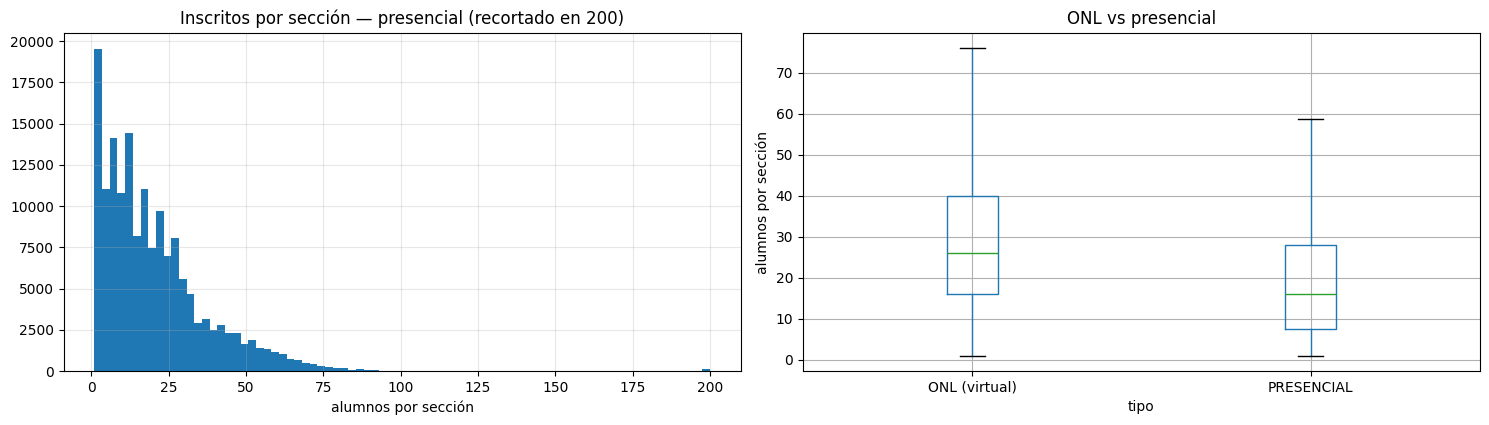

In [26]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 21 · DIAGNÓSTICO · Inscritos por sección — de dónde sale TOPE_SECCION
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Explora la distribución de INSCRITOS/n_secciones por campus y
##            componente para fijar con evidencia el umbral sobre el cual una
##            'sección' deja de ser una clase.
## ENTRADA  : demanda
## SALIDA   : — (solo diagnóstico: tablas y dos gráficos)
## CLAVE    : El hallazgo que fija el umbral: en PRESENCIAL el p99 es 76,5 y el
##            p99,9 es 168 → 300 aísla lo anómalo sin tocar cursos legítimos.
##            ONL es otro mundo (p99 = 348), por eso queda exento del filtro en
##            la celda 22.
## ──────────────────────────────────────────────────────────────────────────────
# ── Diagnóstico · INSCRITOS POR SECCIÓN (para definir el tope) ───────────────
# Grano: PERIODO × asignatura × componente × campus  ->  INSCRITOS / n_secciones
# Es el nº real de alumnos por sección. Sirve para fijar a partir de qué valor
# una "sección" deja de ser una clase y pasa a ser una actividad masiva.

import matplotlib.pyplot as plt

_ps = demanda.assign(
    asignatura=demanda['MATERIA'].astype(str) + demanda['CURSO'].astype(str),
    x_seccion=demanda['INSCRITOS'] / demanda['n_secciones'].replace(0, np.nan))

print("═" * 78); print("DISTRIBUCIÓN DE INSCRITOS POR SECCIÓN"); print("═" * 78)
print(_ps['x_seccion'].describe(percentiles=[.5,.75,.9,.95,.99,.995,.999]).round(1).to_string())

print("\n" + "═" * 78); print("PERCENTILES POR CAMPUS (ONL vs presencial)"); print("═" * 78)
_g = _ps.assign(tipo=np.where(_ps['CAMPUS'] == 'ONL', 'ONL (virtual)', 'PRESENCIAL'))
print(_g.groupby('tipo')['x_seccion']
        .describe(percentiles=[.5,.9,.95,.99,.999]).round(1).to_string())

print("\n" + "═" * 78); print("PERCENTILES POR COMPONENTE (solo presencial)"); print("═" * 78)
print(_g.query("tipo=='PRESENCIAL'").groupby('COMPONENTE')['x_seccion']
        .agg(['count','median','mean',
              ('p90', lambda s: s.quantile(.90)), ('p99', lambda s: s.quantile(.99)), 'max'])
        .sort_values('count', ascending=False).round(1).to_string())

print("\n" + "═" * 78); print("CUÁNTAS FILAS SUPERAN CADA UMBRAL CANDIDATO (presencial)"); print("═" * 78)
_pres = _g.query("tipo=='PRESENCIAL'")
print(f"{'umbral':>8s} {'filas':>10s} {'% filas':>9s} {'asignaturas':>12s} {'inscripciones':>15s}")
for _u in [60, 80, 90, 100, 120, 150, 200, 300, 500]:
    _m = _pres['x_seccion'] > _u
    print(f"{_u:>8d} {_m.sum():>10,} {_m.mean():>9.2%} "
          f"{_pres.loc[_m,'asignatura'].nunique():>12,} {_pres.loc[_m,'INSCRITOS'].sum():>15,}")

print("\n" + "═" * 78); print("TOP 25 — mayores inscritos por sección (presencial)"); print("═" * 78)
print(_pres.nlargest(25, 'x_seccion')[
        ['PERIODO','MATERIA','CURSO','COMPONENTE','CAMPUS','INSCRITOS','n_secciones','x_seccion']]
      .round(1).to_string(index=False))

print("\n" + "═" * 78); print("TOP 15 ASIGNATURAS por su máximo de inscritos por sección (presencial)"); print("═" * 78)
print(_pres.groupby(['MATERIA','CURSO'])
           .agg(max_x_seccion=('x_seccion','max'), mediana=('x_seccion','median'),
                filas=('INSCRITOS','size'), inscritos=('INSCRITOS','sum'))
           .nlargest(15, 'max_x_seccion').round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
_pres['x_seccion'].clip(upper=200).hist(bins=80, ax=ax[0])
ax[0].set_title('Inscritos por sección — presencial (recortado en 200)')
ax[0].set_xlabel('alumnos por sección'); ax[0].grid(alpha=.3)
_g.boxplot(column='x_seccion', by='tipo', ax=ax[1], showfliers=False)
ax[1].set_title('ONL vs presencial'); ax[1].set_ylabel('alumnos por sección'); plt.suptitle('')
plt.tight_layout(); plt.show()

In [27]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 22 · FASE 1 · ESTÁNDAR DE PROGRAMACIÓN (alumnos por sección)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Calcula cuántos alumnos lleva una sección. Dos columnas distintas:
##            `estandar_observado` (por fila, lo que pasó) y
##            `estandar_programacion` (el estándar del grupo, con LAG).
## ENTRADA  : demanda, df2
## SALIDA   : demanda + estandar_observado, estandar_grupo, estandar_programacion,
##            estandar_fuente, estandar_imputado, seccion_masiva,
##            periodo_estandar, estandar_teorico, ratio_ocupacion
## CLAVE    : `estandar_programacion` = PROMEDIO de alumnos por sección del grupo
##            PERÍODO × CAMPUS × COMPONENTE, tomado del período HOMÓLOGO ANTERIOR
##            (mismo TT, año −1). El lag es obligatorio: el promedio del período
##            actual se calcula con los INSCRITOS que se quieren predecir, así que
##            usarlo sería circular (contexto §10). Con lag queda disponible
##            también para períodos futuros. El `estandar_teorico` del catálogo se
##            conserva como referencia comparativa, ya NO como fuente primaria.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · ESTÁNDAR DE PROGRAMACIÓN ────────────────────────────────────────
# Reglas de negocio (Diego, 2026-07-29 — reemplazan la cascada anterior):
#
#  1. `estandar_observado` = INSCRITOS / n_secciones, POR FILA.
#     Es la ocupación real de esa combinación en ese período. Se mantiene igual.
#
#  2. `estandar_programacion` = PROMEDIO de `estandar_observado` del grupo
#     PERÍODO × CAMPUS × COMPONENTE  ——  pero del PERÍODO ANTERIOR, no del actual.
#
#     ⚠️ POR QUÉ EL LAG ES OBLIGATORIO: `estandar_observado` se construye
#     dividiendo por INSCRITOS, que es justo la variable que el modelo predice.
#     Tomar el promedio del MISMO período significa que el estándar ya "sabe"
#     el resultado -> circularidad, y el contexto §10 lo prohíbe explícitamente.
#     Con el lag, además, el estándar existe para períodos que aún no ocurren.
#
#     Búsqueda, en este orden:
#       (a) mismo TT del año anterior          -> lag estacional (202410 → 202510)
#       (b) grupo más reciente ANTES del período (merge_asof backward, sin match
#           exacto) -> cubre lo que no tiene homólogo
#       (c) promedio global histórico          -> último recurso
#
#  3. El nº de SECCIONES no se proyecta: se deriva después por aritmética
#     (ceil(inscritos / estándar)). Lo que se proyecta es el N de inscritos.
#
#  4. Actividades masivas — tratamiento ASIMÉTRICO, y a propósito:
#       · PRESENCIAL (fuera de ONL) > TOPE  -> se EXCLUYE del dataset (R-12).
#         Son actividades institucionales tipo encuesta (EEDD, IAGE, CIVU): no son
#         clases, así que no son demanda de asignatura. 16 asignaturas.
#       · ONL > TOPE_ONL -> se MARCA pero NO se elimina. Son electivos virtuales
#         masivos (CRE2, CBB2, CVRA): cursos reales, aunque con una sección que
#         agrupa miles. Se excluyen solo del cálculo del promedio del grupo, para
#         que no contaminen el estándar del resto.

TOPE_SECCION     = 300     # alumnos por sección: sobre esto no es una clase
TOPE_SECCION_ONL = 300     # ONL tiene su propio tope. Su p99 REAL es 145,3
                           # (la nota antigua decía 348: estaba desactualizada)
EXCLUIR_MASIVAS_PRESENCIALES = True   # R-12: mantiene el saneamiento acordado
AGG_GRUPO = 'mean'         # promedio, por regla de negocio

demanda = demanda.drop(columns=['estandar_programacion','estandar_teorico','estandar_observado',
                                'estandar_grupo','periodo_estandar','estandar_imputado',
                                'estandar_fuente','ratio_ocupacion','seccion_masiva',
                                'maximos_estudiantes_seccion','_est_lag1y','_est_esp'],
                       errors='ignore')

# ── (1) ESTÁNDAR OBSERVADO — por fila ────────────────────────────────────────
demanda['estandar_observado'] = demanda['INSCRITOS'] / demanda['n_secciones'].replace(0, np.nan)

# ── Marca de actividad masiva (no elimina filas) ─────────────────────────────
_tope = np.where(demanda['CAMPUS'] == 'ONL', TOPE_SECCION_ONL, TOPE_SECCION)
demanda['seccion_masiva'] = demanda['estandar_observado'] > _tope

print("═" * 78); print("ACTIVIDADES MASIVAS"); print("═" * 78)
print(f"Topes: presencial {TOPE_SECCION} · ONL {TOPE_SECCION_ONL}")
print(f"Filas sobre el tope: {demanda['seccion_masiva'].sum():,} "
      f"({demanda['seccion_masiva'].mean():.3%})  |  inscripciones "
      f"{demanda.loc[demanda['seccion_masiva'],'INSCRITOS'].sum():,}")
if demanda['seccion_masiva'].any():
    print(demanda[demanda['seccion_masiva']]
          .groupby(['CAMPUS','MATERIA','CURSO','COMPONENTE'], observed=True)
          .agg(filas=('INSCRITOS','size'), inscritos=('INSCRITOS','sum'),
               max_x_seccion=('estandar_observado','max'))
          .sort_values('inscritos', ascending=False).head(12).round(0).to_string())

# ── R-12 · exclusión de las masivas PRESENCIALES (no de las ONL) ─────────────
# Se excluye la ASIGNATURA completa, no solo la fila que superó el tope: si una
# asignatura es una encuesta institucional, lo es en todos sus períodos.
if EXCLUIR_MASIVAS_PRESENCIALES:
    _masiva_pres = (demanda.loc[demanda['seccion_masiva'] & (demanda['CAMPUS'] != 'ONL'),
                                ['MATERIA','CURSO']].drop_duplicates())
    if len(_masiva_pres):
        _n0 = len(demanda)
        _ins0 = demanda['INSCRITOS'].sum()
        demanda = (demanda.merge(_masiva_pres.assign(_drop=1), on=['MATERIA','CURSO'], how='left')
                          .query('_drop.isna()').drop(columns='_drop').reset_index(drop=True))
        print(f"\n>>> R-12 · EXCLUIDAS del dataset {len(_masiva_pres):,} asignaturas presenciales | "
              f"{_n0-len(demanda):,} filas | {_ins0-demanda['INSCRITOS'].sum():,} inscripciones")
        print(f"    Dataset: {_n0:,} -> {len(demanda):,} filas")

print("\nONL sobre el tope: se MARCA (`seccion_masiva`) pero NO se elimina — son electivos")
print("virtuales reales. Solo queda fuera del cálculo del promedio, para no contaminarlo.")

# ── (2) ESTÁNDAR DEL GRUPO: promedio por PERÍODO × CAMPUS × COMPONENTE ───────
_G = ['PERIODO', 'CAMPUS', 'COMPONENTE']
_grupo = (demanda[~demanda['seccion_masiva']]
          .groupby(_G, observed=True)['estandar_observado']
          .agg([(AGG_GRUPO, AGG_GRUPO), ('n', 'size')]).reset_index()
          .rename(columns={AGG_GRUPO: 'estandar_grupo'}))
print("\n" + "═" * 78); print(f"ESTÁNDAR DEL GRUPO ({AGG_GRUPO} de alumnos por sección)"); print("═" * 78)
print(f"Grupos PERÍODO × CAMPUS × COMPONENTE: {len(_grupo):,}")
print(_grupo['estandar_grupo'].describe(percentiles=[.25,.5,.75,.95]).round(2).to_string())

# ── (a) lag estacional: el grupo del mismo TT del año anterior ───────────────
_lag = _grupo[_G + ['estandar_grupo']].copy()
_lag['PERIODO'] = _lag['PERIODO'] + 100                     # se ofrece al año siguiente
demanda = demanda.merge(_lag.rename(columns={'estandar_grupo': '_est_lag1y'}),
                        on=_G, how='left')

# ── (b) espiral hacia atrás: grupo más reciente ANTES del período ────────────
# allow_exact_matches=False es lo que GARANTIZA que nunca se use el período
# actual: sin eso volvería la circularidad por la puerta de atrás.
_gp = _grupo[_G + ['estandar_grupo']].sort_values('PERIODO', ignore_index=True)
_dd = demanda[_G].drop_duplicates().sort_values('PERIODO', ignore_index=True)
_esp = pd.merge_asof(_dd, _gp, on='PERIODO', by=['CAMPUS', 'COMPONENTE'],
                     direction='backward', allow_exact_matches=False)
demanda = demanda.merge(_esp.rename(columns={'estandar_grupo': '_est_esp'}), on=_G, how='left')

# ── (c) cascada final ───────────────────────────────────────────────────────
_global = float(demanda.loc[~demanda['seccion_masiva'], 'estandar_observado'].mean())
demanda['estandar_programacion'] = demanda['_est_lag1y'].fillna(demanda['_est_esp']).fillna(_global)
demanda['estandar_fuente'] = np.select(
    [demanda['_est_lag1y'].notna(), demanda['_est_esp'].notna()],
    ['grupo_lag_1y', 'grupo_espiral_atras'], default='promedio_global')
demanda['estandar_imputado'] = demanda['estandar_fuente'] != 'grupo_lag_1y'
demanda['estandar_grupo'] = demanda['_est_lag1y']          # trazabilidad del valor con lag
demanda = demanda.drop(columns=['_est_lag1y', '_est_esp'])

print("\n" + "═" * 78); print("ORIGEN DEL ESTÁNDAR DE PROGRAMACIÓN"); print("═" * 78)
print(demanda['estandar_fuente'].value_counts().to_string())
print(f"\n  grupo_lag_1y        = promedio del mismo TT del año anterior (lo esperado)")
print(f"  grupo_espiral_atras = no había homólogo; se usa el grupo previo más cercano")
print(f"  promedio_global     = {_global:.2f} alumnos/sección (sin ningún grupo previo)")
print(f"\nCobertura: {demanda['estandar_programacion'].notna().mean():.1%}")
print(demanda['estandar_programacion'].describe(percentiles=[.25,.5,.75,.95]).round(2).to_string())

# ── ESTÁNDAR TEÓRICO del catálogo — ahora solo como REFERENCIA ───────────────
# Ya no alimenta `estandar_programacion`, pero se conserva para poder contrastar
# la capacidad declarada contra la ocupación real (`ratio_ocupacion`).
_teo = (df2[['periodo_scacrse','cod_materia','n_curso','componente','maximos_estudiantes_seccion']]
        .dropna(subset=['periodo_scacrse','cod_materia','n_curso','componente'])
        .groupby(['cod_materia','n_curso','componente','periodo_scacrse'], as_index=False)
        ['maximos_estudiantes_seccion'].max())
_teo = _teo[_teo['periodo_scacrse'] != 999996]
_teo['periodo_scacrse'] = _teo['periodo_scacrse'].astype('int64')
_LA = ['MATERIA', 'CURSO', 'COMPONENTE']
_p = (_teo.rename(columns={'cod_materia':'MATERIA','n_curso':'CURSO','componente':'COMPONENTE'})
          .sort_values('periodo_scacrse', ignore_index=True))
_d = demanda[['PERIODO'] + _LA].drop_duplicates().sort_values('PERIODO', ignore_index=True)
_ade = pd.merge_asof(_d, _p, left_on='PERIODO', right_on='periodo_scacrse', by=_LA, direction='forward')
_atr = pd.merge_asof(_d, _p, left_on='PERIODO', right_on='periodo_scacrse', by=_LA, direction='backward')
_res = _ade.copy(); _f = _res['periodo_scacrse'].isna()
for _c in ['periodo_scacrse', 'maximos_estudiantes_seccion']:
    _res.loc[_f, _c] = _atr.loc[_f, _c]
demanda = demanda.merge(_res.rename(columns={'periodo_scacrse': 'periodo_estandar',
                                             'maximos_estudiantes_seccion': 'estandar_teorico'}),
                        on=['PERIODO'] + _LA, how='left')

demanda['ratio_ocupacion'] = (demanda['estandar_observado'] /
                              demanda['estandar_teorico'].replace(0, np.nan))
_ct = demanda['ratio_ocupacion'].notna()
print("\n" + "═" * 78); print("REFERENCIA — ocupación real vs capacidad del catálogo"); print("═" * 78)
print(f"Filas con estandar_teorico: {demanda['estandar_teorico'].notna().sum():,} "
      f"({demanda['estandar_teorico'].notna().mean():.1%})  |  en cero: "
      f"{(demanda['estandar_teorico'] == 0).sum():,}")
print(demanda.loc[_ct, 'ratio_ocupacion'].describe(percentiles=[.25,.5,.75,.9]).round(2).to_string())
print("  1.0 = se llena justo al teórico | <1 = holgura | >1 = sobrecupo")

# ── VALIDACIÓN: ¿reconstruye el nº de secciones? (con demanda REAL) ──────────
# Es el TECHO de la conversión: con los inscritos verdaderos, cuánto acierta la
# aritmética. El error que quede aquí es de la fórmula, no del modelo de demanda.
print("\n" + "═" * 78); print("VALIDACIÓN — ceil(INSCRITOS / estándar) vs secciones reales"); print("═" * 78)
_ok = demanda['estandar_programacion'] > 0
_se = np.ceil(demanda.loc[_ok, 'INSCRITOS'] / demanda.loc[_ok, 'estandar_programacion']).clip(lower=1)
_sr = demanda.loc[_ok, 'n_secciones']
print(f"Secciones estimadas: {_se.sum():,.0f} | reales: {_sr.sum():,.0f} | "
      f"dif {(_se.sum()/_sr.sum()-1)*100:+.1f}%")
print(f"Exactas: {(_se == _sr).mean():.1%} | sub: {(_se < _sr).mean():.1%} | "
      f"sobre: {(_se > _sr).mean():.1%} | MAE: {(_se-_sr).abs().mean():.2f}")
print("\n⚠️ Estos números NO son comparables con los de la versión anterior: antes el")
print("   estándar venía del catálogo y del promedio del MISMO período (circular), lo")
print("   que inflaba la exactitud. Ahora todo sale de períodos cerrados.")

demanda[['PERIODO','MATERIA','CURSO','COMPONENTE','CAMPUS','INSCRITOS','n_secciones',
         'estandar_observado','estandar_programacion','estandar_fuente','seccion_masiva',
         'estandar_teorico']].head(10)


══════════════════════════════════════════════════════════════════════════════
ACTIVIDADES MASIVAS
══════════════════════════════════════════════════════════════════════════════
Topes: presencial 300 · ONL 300
Filas sobre el tope: 165 (0.100%)  |  inscripciones 344,575
                                 filas  inscritos  max_x_seccion
CAMPUS MATERIA CURSO COMPONENTE                                 
TPC    EEDD    0002  TEO             5      51423         6653.0
LPS    EEDD    0002  TEO             4      29731         7908.0
PAP    EEDD    0002  TEO             5      24343         6344.0
ONL    EEDD    0001  ELG             6      19626         3908.0
BES    EEDD    0002  TEO             4      18470         4721.0
CVA    EEDD    0002  TEO             4      15872         4405.0
TPC    IAGE    0001  NPR             1      12156         6078.0
ONL    CBB2    0002  ELG             4      11075         1589.0
TPC    CIVU    A001  LAB             4      11008         3301.0
BES    EEDD    

,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,n_secciones,estandar_observado,estandar_programacion,estandar_fuente,seccion_masiva,estandar_teorico
0,201610,ACPI,P002,AYU,BES,63,2,31.5,18.250000,grupo_espiral_atras,False,60.0
1,201510,ACPI,P002,LAB,BES,60,2,30.0,20.528627,promedio_global,False,NaN
2,201610,ACPI,P002,LAB,BES,63,3,21.0,21.586645,grupo_lag_1y,False,NaN
3,201710,ACPI,P002,LAB,BES,34,2,17.0,21.061571,grupo_lag_1y,False,NaN
4,201810,ACPI,P002,LAB,BES,39,2,19.5,19.263737,grupo_lag_1y,False,NaN
5,201910,ACPI,P002,LAB,BES,56,2,28.0,19.379034,grupo_lag_1y,False,NaN
6,202010,ACPI,P002,LAB,BES,3,1,3.0,19.410781,grupo_lag_1y,False,NaN
7,201510,ACPI,P002,LAB,CVA,59,2,29.5,20.528627,promedio_global,False,NaN
8,201610,ACPI,P002,LAB,CVA,41,2,20.5,17.833846,grupo_lag_1y,False,NaN
9,201710,ACPI,P002,LAB,CVA,34,2,17.0,16.900150,grupo_lag_1y,False,NaN


In [28]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 23 · FASE 1 · NULOS DE LOS LAGS — por qué NO se imputan
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Añade indicadores que hacen explícito lo que significa cada NaN de
##            los lags, en vez de rellenarlos.
## ENTRADA  : demanda
## SALIDA   : demanda + n_periodos_historia, antiguedad_serie, es_serie_nueva,
##            sin_historia_estacional
## CLAVE    : Los nulos de los lags son ESTRUCTURALES, no datos perdidos: la
##            serie no tiene historia previa. Rellenar con 0 afirmaría 'hubo
##            cero demanda el año pasado', que es falso y distinto de 'no
##            sabemos'; con la media se inventaría una historia y se aplanaría
##            justo la señal que separa una asignatura nueva de una consolidada.
##            LightGBM maneja NaN nativamente (aprende hacia qué lado enviarlos
##            en cada split). SMOTE NO aplica: es para desbalance de clases en
##            clasificación, aquí hay regresión sobre conteos y sintetizar filas
##            rompería el orden temporal.
## ──────────────────────────────────────────────────────────────────────────────
# ── Fase 1 · Tratamiento de los nulos de la ingeniería de variables (lags) ───
# Los nulos de los lags NO son datos perdidos: son ESTRUCTURALES — la serie no
# tiene historia previa (asignatura nueva, primer periodo, o hueco en la serie).
#
# Por eso NO se imputan con un valor:
#   - Rellenar con 0 le diria al modelo "hubo cero demanda el año pasado", que es
#     una afirmacion falsa y distinta de "no sabemos".
#   - Rellenar con la media inventaria una historia que no existe y aplanaria
#     justo la señal que distingue a una asignatura nueva de una consolidada.
#   - SMOTE no aplica: es para desbalance de CLASES en clasificacion; aqui hay
#     regresion sobre conteos, y sintetizar filas romperia el orden temporal.
#
# LightGBM maneja NaN de forma nativa (aprende hacia que lado enviarlos en cada
# split), asi que la mejor estrategia es DEJARLOS y ademas hacer explicita la
# informacion que el nulo contiene, con indicadores de madurez de la serie.

_ind = ['n_periodos_historia', 'antiguedad_serie', 'es_serie_nueva', 'sin_historia_estacional']
demanda = demanda.drop(columns=_ind, errors='ignore')   # idempotente

demanda = demanda.sort_values(SERIE + ['PERIODO'], ignore_index=True)
_g = demanda.groupby(SERIE)

# Cuantos periodos previos tiene la serie en este punto del tiempo (no mira el futuro)
demanda['n_periodos_historia'] = _g.cumcount()
# Distancia en años desde la primera aparicion de la serie
demanda['antiguedad_serie'] = demanda['ANIO'] - _g['ANIO'].transform('min')
# Banderas explicitas de por que faltan los lags
demanda['es_serie_nueva']          = demanda['n_periodos_historia'] == 0
demanda['sin_historia_estacional'] = demanda['ins_lag_1y'].isna()

print("Indicadores de madurez de la serie (hacen explicito lo que significa el NaN):")
print(f"  es_serie_nueva=True          : {demanda['es_serie_nueva'].sum():,} "
      f"({demanda['es_serie_nueva'].mean():.1%})  <- primer periodo de la serie")
print(f"  sin_historia_estacional=True : {demanda['sin_historia_estacional'].sum():,} "
      f"({demanda['sin_historia_estacional'].mean():.1%})  <- sin el mismo TT del año anterior")
print("\nn_periodos_historia:")
print(demanda['n_periodos_historia'].describe().to_string())

print("\n" + "=" * 74)
print("NULOS QUE SE DEJAN A PROPOSITO (los resuelve LightGBM nativamente)")
print("=" * 74)
for c in ['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y', 'ins_roll_mean_3y', 'ins_roll_std_3y',
          'ins_lag_prev', 'reprob_idx_lag_1y', 'reprob_n_lag_1y', 'reprob_n_prev', 'reprob_idx_prev']:
    print(f"  {c:22s}: {demanda[c].isna().sum():>7,} nulos ({demanda[c].isna().mean():5.1%})")

print("\n¿La ausencia de historia es informativa? Demanda promedio por tipo de serie:")
print(demanda.groupby('es_serie_nueva')['INSCRITOS'].agg(['count', 'mean', 'median']).round(1).to_string())

demanda[['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE', 'INSCRITOS', 'n_periodos_historia',
         'antiguedad_serie', 'es_serie_nueva', 'sin_historia_estacional', 'ins_lag_1y']].head(12)

Indicadores de madurez de la serie (hacen explicito lo que significa el NaN):
  es_serie_nueva=True          : 28,996 (17.7%)  <- primer periodo de la serie
  sin_historia_estacional=True : 50,038 (30.5%)  <- sin el mismo TT del año anterior

n_periodos_historia:
count    163954.000000
mean          4.819297
std           4.826721
min           0.000000
25%           1.000000
50%           3.000000
75%           7.000000
max          33.000000

NULOS QUE SE DEJAN A PROPOSITO (los resuelve LightGBM nativamente)
  ins_lag_1y            :  50,038 nulos (30.5%)
  ins_lag_2y            :  76,147 nulos (46.4%)
  ins_lag_3y            :  97,043 nulos (59.2%)
  ins_roll_mean_3y      :  44,430 nulos (27.1%)
  ins_roll_std_3y       :  76,036 nulos (46.4%)
  ins_lag_prev          :  28,996 nulos (17.7%)
  reprob_idx_lag_1y     :  52,515 nulos (32.0%)
  reprob_n_lag_1y       :  52,133 nulos (31.8%)
  reprob_n_prev         :  31,922 nulos (19.5%)
  reprob_idx_prev       :  32,538 nulos (19.8%)

¿La

,PERIODO,MATERIA,CURSO,COMPONENTE,INSCRITOS,n_periodos_historia,antiguedad_serie,es_serie_nueva,sin_historia_estacional,ins_lag_1y
0,201610,ACPI,P002,AYU,63,0,0,True,True,NaN
1,201510,ACPI,P002,LAB,60,0,0,True,True,NaN
2,201610,ACPI,P002,LAB,63,1,1,False,False,60.0
3,201710,ACPI,P002,LAB,34,2,2,False,False,63.0
4,201810,ACPI,P002,LAB,39,3,3,False,False,34.0
5,201910,ACPI,P002,LAB,56,4,4,False,False,39.0
6,202010,ACPI,P002,LAB,3,5,5,False,False,56.0
7,201510,ACPI,P002,LAB,59,0,0,True,True,NaN
8,201610,ACPI,P002,LAB,41,1,1,False,False,59.0
9,201710,ACPI,P002,LAB,34,2,2,False,False,41.0


In [29]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 24 · VALIDACIÓN · Auditoría del merge para una asignatura
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Traza una asignatura concreta de punta a punta: qué hay en df2 →
##            qué quedó en las pivots → qué trajo el merge a la sábana, con
##            diagnóstico automático.
## ENTRADA  : df2, pivot_df2_1, pivot_df2_2, demanda
## SALIDA   : — (solo diagnóstico)
## CLAVE    : Cambiar MATERIA_CHK / CURSO_CHK para auditar cualquier asignatura.
##            El bloque [5] da el panorama global: cuántas asignaturas quedaron
##            sin atributos y cuántas de ésas existen en df2 (o sea, son
##            rescatables) frente a las que simplemente no están.
## ──────────────────────────────────────────────────────────────────────────────
# ── Validación del merge de atributos para una asignatura ────────────────────
# Trazabilidad completa: que hay en df2 -> que quedo en la pivot -> que trajo el merge.
# Cambia MATERIA_CHK / CURSO_CHK para auditar cualquier asignatura.

MATERIA_CHK, CURSO_CHK = 'ACPI', 'P001'

_f2  = df2[(df2['cod_materia'] == MATERIA_CHK) & (df2['n_curso'] == CURSO_CHK)]
_p1  = pivot_df2_1[(pivot_df2_1['cod_materia'] == MATERIA_CHK) & (pivot_df2_1['n_curso'] == CURSO_CHK)]
_p2  = pivot_df2_2[(pivot_df2_2['cod_materia'] == MATERIA_CHK) & (pivot_df2_2['n_curso'] == CURSO_CHK)]
_dem = demanda[(demanda['MATERIA'] == MATERIA_CHK) & (demanda['CURSO'] == CURSO_CHK)]

print("=" * 78)
print(f"AUDITORIA DE MATCH — {MATERIA_CHK} {CURSO_CHK}")
print("=" * 78)

# 1) ¿Existe en df2 y con que atributos?
print(f"\n[1] En df2 (catalogo completo): {len(_f2):,} filas  |  de esas vigente==True: {(_f2['vigente'] == True).sum():,}")
if len(_f2):
    print(_f2[['cod_programa_carrera', 'periodo_reglas', 'vigente', 'periodo_scacrse', 'componente',
               'carga_semanal', 'hr_teo', 'hr_lab', 'hr_otro', 'departamento/form_general']]
          .drop_duplicates().sort_values(['vigente', 'periodo_scacrse']).head(12).to_string(index=False))

# 2) ¿Esta en las pivots?
print(f"\n[2] En pivot_df2_1 (atributos, sin filtro): {len(_p1):,} filas")
if len(_p1):
    print(_p1.to_string(index=False))
print(f"\n    En pivot_df2_2 (solo mallas vigentes)  : {len(_p2):,} filas")

# 3) ¿Que trajo el merge a demanda?
print(f"\n[3] En demanda: {len(_dem):,} filas")
if len(_dem):
    print(_dem[['PERIODO', 'COMPONENTE', 'CAMPUS', 'INSCRITOS', 'periodo_atrib', 'tipo_match',
                'carga_semanal', 'hr_teo', 'hr_lab', 'vigente']].head(12).to_string(index=False))

# 4) Diagnostico
print("\n[4] DIAGNOSTICO")
if len(_f2) == 0:
    print("    La asignatura no existe en df2 -> no hay atributos posibles.")
elif len(_dem) == 0:
    print("    La asignatura no tiene inscripciones en el periodo cargado.")
elif _dem['carga_semanal'].notna().any():
    print("    Match OK: la asignatura tiene atributos en demanda.")
    print(f"    Vias de match usadas: {_dem['tipo_match'].value_counts().to_dict()}")
    if len(_p2) == 0:
        print("    Nota: no aparece en ninguna malla vigente -> 'vigente' queda nulo (correcto).")
else:
    print("    Tiene atributos en df2 pero el merge no pego: revisar componente o periodo.")
    print(f"    Componentes en df2: {sorted(_f2['componente'].dropna().unique())}")
    print(f"    Componentes en demanda: {sorted(_dem['COMPONENTE'].unique())}")

# 5) Panorama global
print("\n[5] GLOBAL")
_sin = demanda[demanda['carga_semanal'].isna()][['MATERIA', 'CURSO']].drop_duplicates()
_en_df2 = df2[['cod_materia', 'n_curso']].drop_duplicates().rename(
    columns={'cod_materia': 'MATERIA', 'n_curso': 'CURSO'})
_rescatables = _sin.merge(_en_df2, on=['MATERIA', 'CURSO'], how='inner')
_con = demanda['carga_semanal'].notna()
print(f"    Filas de demanda con atributos : {_con.sum():,} ({_con.mean():.1%})")
print(f"    Asignaturas sin atributos      : {len(_sin):,}")
print(f"      - existen en df2 (revisar)   : {len(_rescatables):,}")
print(f"      - no existen en df2          : {len(_sin) - len(_rescatables):,}")

AUDITORIA DE MATCH — ACPI P001

[1] En df2 (catalogo completo): 21 filas  |  de esas vigente==True: 0
cod_programa_carrera  periodo_reglas  vigente  periodo_scacrse componente  carga_semanal  hr_teo  hr_lab  hr_otro departamento/form_general
       PBMAUGD1&PBMA          201010    False         201410.0        LAB            2.0     4.0     2.0      2.0                      0000
       PBMAUGD1&PBMA          201010    False         201410.0        AYU            2.0     4.0     2.0      2.0                      0000
       PBMAUGD1&PBMA          201010    False         201410.0        TEO            4.0     4.0     2.0      2.0                      0000
       PEGBUGD1&PEGB          201010    False         201410.0        LAB            2.0     4.0     2.0      2.0                      0000
       PEGBUGD1&PEGB          201010    False         201410.0        AYU            2.0     4.0     2.0      2.0                      0000
       PEGBUGD1&PEGB          201010    False         2014

In [30]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 24b · FASE 1 · REGLA Y TRAZABILIDAD EN LA SÁBANA
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Agrega a la sábana el código de REGLA con que quedó cada asignatura
##            y los códigos ORIGINALES que se fusionaron en ella.
## ENTRADA  : demanda · df (con MATERIA_ORIGEN/CURSO_ORIGEN) · homologacion_log
## SALIDA   : demanda + ASIGNATURA, REGLA, CODIGOS_ORIGEN, N_CODIGOS_ORIGEN
## CLAVE    : Va ANTES del export (celda 25) para que las columnas viajen al
##            parquet que consume el notebook de ML.
##            `MATERIA`/`CURSO` en la sábana YA son el código homologado — el de
##            la regla. `CODIGOS_ORIGEN` es lo único que permite volver atrás,
##            porque la agregación de la celda 8 funde varios orígenes en una
##            fila y `MATERIA_ORIGEN` no sobrevive a ese groupby.
## ──────────────────────────────────────────────────────────────────────────────

demanda['ASIGNATURA'] = demanda['MATERIA'].astype(str) + demanda['CURSO'].astype(str)

# ── Códigos originales que alimentan cada asignatura homologada ─────────────
if 'MATERIA_ORIGEN' in df.columns:
    _t = pd.DataFrame({
        '_dst': df['MATERIA'].astype(str) + df['CURSO'].astype(str),
        '_org': df['MATERIA_ORIGEN'].astype(str) + df['CURSO_ORIGEN'].astype(str)})
    _agg = (_t.drop_duplicates().groupby('_dst')['_org']
              .agg(CODIGOS_ORIGEN=lambda s: '|'.join(sorted(set(s))),
                   N_CODIGOS_ORIGEN='nunique'))
    demanda['CODIGOS_ORIGEN'] = demanda['ASIGNATURA'].map(_agg['CODIGOS_ORIGEN'])
    demanda['N_CODIGOS_ORIGEN'] = (demanda['ASIGNATURA'].map(_agg['N_CODIGOS_ORIGEN'])
                                   .fillna(1).astype(int))
else:
    demanda['CODIGOS_ORIGEN'] = demanda['ASIGNATURA']
    demanda['N_CODIGOS_ORIGEN'] = 1
    print("⚠️ `df` no trae MATERIA_ORIGEN: la celda 7b no corrió.")

# ── Regla con que quedó cada asignatura ─────────────────────────────────────
# Las que la cascada resolvió tienen regla; las 'sin cruce' quedan en NaN, que es
# información útil: son las que ninguna malla reconoce.
if 'homologacion_log' in globals():
    _resueltas = set(homologacion_log['REGLA_ASIGNADA']) | \
                 set(homologacion_log.loc[~homologacion_log['CAMBIA_CODIGO'], 'COD_ORIGEN'])
    demanda['REGLA'] = demanda['ASIGNATURA'].where(demanda['ASIGNATURA'].isin(_resueltas))
else:
    demanda['REGLA'] = pd.NA
    print("⚠️ falta `homologacion_log`: ejecutar la celda 7b.")

# ── Guards ──────────────────────────────────────────────────────────────────
if demanda['ASIGNATURA'].isna().any():
    raise ValueError("Hay filas sin ASIGNATURA.")
_mult = demanda[demanda['N_CODIGOS_ORIGEN'] > 1]

print("═" * 78)
print("REGLA Y TRAZABILIDAD EN LA SÁBANA")
print("═" * 78)
print(f"  filas de la sábana        : {len(demanda):,}")
print(f"  asignaturas distintas     : {demanda['ASIGNATURA'].nunique():,}")
print(f"  con REGLA asignada        : {demanda['REGLA'].notna().sum():,} filas "
      f"({demanda['REGLA'].notna().mean():.1%}) | "
      f"{demanda.loc[demanda['REGLA'].notna(), 'INSCRITOS'].sum():,} inscritos")
print(f"  SIN regla (ninguna malla) : {demanda['REGLA'].isna().sum():,} filas | "
      f"{demanda.loc[demanda['REGLA'].isna(), 'INSCRITOS'].sum():,} inscritos")
print(f"\n  asignaturas que FUSIONAN varios códigos : "
      f"{_mult['ASIGNATURA'].nunique():,}")
print(f"  máximo de códigos fusionados en una      : "
      f"{int(demanda['N_CODIGOS_ORIGEN'].max())}")

print("\n  Las que más códigos fusionan:")
print(demanda.nlargest(6, 'N_CODIGOS_ORIGEN')[['ASIGNATURA', 'N_CODIGOS_ORIGEN',
                                               'CODIGOS_ORIGEN']]
      .drop_duplicates('ASIGNATURA').to_string(index=False))


══════════════════════════════════════════════════════════════════════════════
REGLA Y TRAZABILIDAD EN LA SÁBANA
══════════════════════════════════════════════════════════════════════════════
  filas de la sábana        : 163,954
  asignaturas distintas     : 7,732
  con REGLA asignada        : 160,354 filas (97.8%) | 6,885,684 inscritos
  SIN regla (ninguna malla) : 3,600 filas | 196,504 inscritos

  asignaturas que FUSIONAN varios códigos : 1,181
  máximo de códigos fusionados en una      : 13

  Las que más códigos fusionan:
ASIGNATURA  N_CODIGOS_ORIGEN                                                                                                       CODIGOS_ORIGEN
  DSPU0011                13 FONA0031|KINE0039|KINEG006|NYGAG002|QYFA1035|TEOCH006|TMED0080|TMED0083|TMED0086|TMEDJ003|TMEDJ007|TMEDJ010|TMEDJ013


In [31]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 24c · FASE 1 · PERCENTILES DE OCUPACIÓN POR SECCIÓN
## ══════════════════════════════════════════════════════════════════════════════
## POR QUÉ AQUÍ Y NO EN EL ML:
##   Los percentiles necesitan los inscritos POR NRC, y el NRC sólo existe en el
##   detalle de inscripción (`df`, 385 MB). La sábana ya viene agregada y lo perdió.
##   Calcularlos aquí —donde el detalle ya está cargado y homologado— cuesta ~6 s;
##   hacerlo en el notebook de ML obligaría a releer el CSV grande en cada corrida.
##
## QUÉ SON: la distribución del TAMAÑO DE SECCIÓN observado. Para cada
##   `PERIODO × COMPONENTE × CAMPUS` se mira cuántos alumnos tuvo cada NRC y se
##   resumen sus cuartiles. Responden "¿de qué tamaño son las secciones aquí?".
##
## ⚠️ EL GRANO ES COMPONENTE × CAMPUS, NO la combinación de la fila. Medido: al
##    grano fino el 79% de las combinaciones tiene <=2 secciones, así que los 4
##    percentiles colapsan al mismo número y el abanico p90/p25 queda en 1,2x.
##    A nivel de componente el abanico es real — de 1,1x en SIM a 9,3x en ELG.
##
## ⚠️ NO SON FEATURES DEL MODELO. Dependen de los inscritos del propio período
##    (§10 anti-leakage). Son insumo de la conversión a secciones, que ocurre
##    DESPUÉS de proyectar la demanda.
##
## ENTRADA : `df` (detalle homologado, con NRC) · `demanda` (la sábana)
## SALIDA  : 4 columnas nuevas en `demanda` — estandar_p25/p50/p75/p90
## ──────────────────────────────────────────────────────────────────────────────
_PCT = [25, 50, 75, 90]
_GPC = ['PERIODO', 'COMPONENTE', 'CAMPUS']
_COLS_PCT = [f'estandar_p{p}' for p in _PCT]

print("═" * 78)
print("PERCENTILES DE OCUPACIÓN POR SECCIÓN")
print("═" * 78)

demanda = demanda.drop(columns=[c for c in _COLS_PCT if c in demanda.columns])  # idempotente
_n0 = len(demanda)

# ── A) Grano SECCIÓN: cuántos alumnos tuvo cada NRC ──────────────────────────
# El NRC sólo es único DENTRO de su período (se reutiliza: 77% reaparece en otro),
# así que PERIODO entra en la llave — si no, se colapsarían secciones distintas.
_sec = (df[df['RUT'].notna()]
        .groupby(['PERIODO', 'NRC'] + dims[1:], observed=True)['RUT']
        .count().rename('_ins').reset_index())
print(f"  secciones individuales (NRC × período): {len(_sec):,}")
print(f"  ocupación por sección: p25 {_sec['_ins'].quantile(.25):.0f} · "
      f"p50 {_sec['_ins'].median():.0f} · p75 {_sec['_ins'].quantile(.75):.0f} · "
      f"p90 {_sec['_ins'].quantile(.90):.0f}")

# ── B) Percentiles por PERIODO × COMPONENTE × CAMPUS ─────────────────────────
_gb = _sec.groupby(_GPC, observed=True)['_ins']
_pc = pd.DataFrame({f'estandar_p{p}': _gb.quantile(p / 100) for p in _PCT})
_pc['_n_sec'] = _gb.size()
print(f"  grupos {' × '.join(_GPC)}: {len(_pc):,}")

# grupos con muy pocas secciones: el percentil es ruido, se marcan pero no se borran
_pocos = (_pc['_n_sec'] < 10).sum()
print(f"  con <10 secciones (percentil poco fiable): {_pocos:,} ({_pocos/len(_pc):.1%})")

demanda = demanda.merge(_pc[_COLS_PCT].reset_index(), on=_GPC, how='left')

# ── C) Guards ────────────────────────────────────────────────────────────────
if len(demanda) != _n0:
    raise ValueError(f"el merge de percentiles duplicó filas: {_n0:,} -> {len(demanda):,}")
_cob = demanda[_COLS_PCT].notna().all(axis=1).mean()
if _cob < 0.99:
    raise ValueError(f"cobertura de percentiles demasiado baja: {_cob:.1%}")
# monotonía: p25 <= p50 <= p75 <= p90, por definición de cuantil
for _a, _b in zip(_COLS_PCT, _COLS_PCT[1:]):
    _mal = (demanda[_a] > demanda[_b] + 1e-9).sum()
    if _mal:
        raise ValueError(f"{_mal:,} filas con {_a} > {_b}: los cuantiles no son monótonos")
print(f"  ✅ cobertura {_cob:.1%} · monotonía p25<=p50<=p75<=p90 verificada")

# ── D) El abanico por componente, que es lo que justifica el grano ───────────
print("\n" + "─" * 78)
print("ABANICO DE TAMAÑO DE SECCIÓN POR COMPONENTE")
print("─" * 78)
_v = demanda[demanda['PERIODO'] // 100 >= demanda['PERIODO'].max() // 100 - 2]
_r = (_v.groupby('COMPONENTE', observed=True)[_COLS_PCT + ['INSCRITOS']]
        .agg({**{c: 'median' for c in _COLS_PCT}, 'INSCRITOS': 'size'})
        .rename(columns={'INSCRITOS': 'filas'}))
_r = _r[_r['filas'] > 200].sort_values('filas', ascending=False)
_r['abanico'] = _r['estandar_p90'] / _r['estandar_p25'].clip(lower=1)
print(f"  {'comp':<6} {'p25':>6} {'p50':>6} {'p75':>6} {'p90':>6} {'abanico':>9}")
for _c, _x in _r.iterrows():
    print(f"  {_c:<6} {_x['estandar_p25']:>6.0f} {_x['estandar_p50']:>6.0f} "
          f"{_x['estandar_p75']:>6.0f} {_x['estandar_p90']:>6.0f} {_x['abanico']:>8.1f}x")
print("""
  📌 Los componentes con abanico ESTRECHO son justo aquellos cuyo estándar
     teórico se cumple (SIM 12, SSA 12, TAL 40): secciones homogéneas porque
     hay un tope efectivo. Donde el estándar no describe la práctica (TEO, ELG)
     las secciones se dispersan y el abanico se abre.""")


══════════════════════════════════════════════════════════════════════════════
PERCENTILES DE OCUPACIÓN POR SECCIÓN
══════════════════════════════════════════════════════════════════════════════
  secciones individuales (NRC × período): 452,695
  ocupación por sección: p25 2 · p50 9 · p75 24 · p90 40
  grupos PERIODO × COMPONENTE × CAMPUS: 2,439
  con <10 secciones (percentil poco fiable): 724 (29.7%)
  ✅ cobertura 100.0% · monotonía p25<=p50<=p75<=p90 verificada

──────────────────────────────────────────────────────────────────────────────
ABANICO DE TAMAÑO DE SECCIÓN POR COMPONENTE
──────────────────────────────────────────────────────────────────────────────
  comp      p25    p50    p75    p90   abanico
  TEO        11     25     48     65      5.9x
  LAB         7     15     25     30      4.3x
  ELG         6     12     22     42      7.7x
  OCS         1      1      3      4      4.0x
  TAL        24     32     38     42      1.8x
  SSA         9     11     12     12      1.3x


In [32]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 25 · ENTREGA · Export de la sábana final → insumo del notebook de ML
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Escribe la sábana en parquet y CSV, y documenta el perfil de nulos
##            por familia de columnas.
## ENTRADA  : demanda
## SALIDA   : DEMANDA_PROCESADA.parquet (lo consume MODELO_ML_*.ipynb) + .csv
##            (para Excel)
## CLAVE    : El PARQUET es el que importa: preserva dtypes (booleanos, enteros
##            con nulos) que el CSV pierde. Entrega 163.954 filas × 61 columnas
##            · 28.996 series · 131 períodos (201510–202627). N_SERIES permite
##            exportar una muestra de series completas para pruebas rápidas;
##            None = sábana completa.
## ──────────────────────────────────────────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════
# ENTREGA · Export de la sábana FINAL de demanda  →  insumo del notebook de ML
# ══════════════════════════════════════════════════════════════════════════════
# Se exporta en dos formatos:
#   .parquet -> es el que consume MODELO_ML_PROYECCION_ASIGNATURAS.ipynb.
#               Preserva dtypes (booleanos, enteros con nulos), que el CSV pierde.
#   .csv     -> para revisar en Excel (sep=';' + utf-8-sig, config. regional es-CL).

N_SERIES = None     # None = sábana completa | int = muestra de N series completas

if N_SERIES is None:
    sabana = demanda.copy()
else:
    _top = (demanda.groupby(SERIE)
                   .agg(n_periodos=('PERIODO', 'nunique'), total=('INSCRITOS', 'sum'))
                   .sort_values(['n_periodos', 'total'], ascending=False)
                   .head(N_SERIES).reset_index()[SERIE])
    sabana = demanda.merge(_top, on=SERIE, how='inner')

sabana = sabana.sort_values(SERIE + ['PERIODO'], ignore_index=True)

salida_parquet = f'{CARPETA}/DEMANDA_PROCESADA.parquet'
salida_csv     = f'{CARPETA}/DEMANDA_PROCESADA.csv'
sabana.to_parquet(salida_parquet, index=False)
# decimal=',' -> Excel en configuracion es-CL espera COMA decimal. Sin esto lee el
# punto como separador de miles y 22.333333333333332 se muestra como
# 22.333.333.333.333.332. Afecta a las 10 columnas con decimales.
sabana.to_csv(salida_csv, sep=';', encoding='utf-8-sig', index=False, decimal=',')

print("═" * 78); print("SÁBANA FINAL EXPORTADA"); print("═" * 78)
print(f"  {salida_parquet}   ({os.path.getsize(salida_parquet)/1e6:.1f} MB)  <- insumo del notebook ML")
print(f"  {salida_csv}   ({os.path.getsize(salida_csv)/1e6:.1f} MB)  <- para Excel")
print(f"\nFilas: {len(sabana):,} | Columnas: {sabana.shape[1]} | Series: {sabana.groupby(SERIE).ngroups:,}")
print(f"Periodos: {sabana['PERIODO'].nunique()} ({sabana['PERIODO'].min()}–{sabana['PERIODO'].max()})")

# ── Perfil de nulos por familia (documenta el estado de entrega) ──
FAMILIAS = {
    'LLAVE / OBJETIVO'      : ['PERIODO','MATERIA','CURSO','COMPONENTE','CAMPUS','INSCRITOS','ANIO','TT'],
    'REPROBACION (periodo)' : ['n_aprobados','n_reprobados','n_registros','n_evaluados',
                               'indice_reprobacion','tasa_reprobacion'],
    'LAGS INSCRITOS'        : ['ins_lag_1y','ins_lag_2y','ins_lag_3y','ins_roll_mean_3y',
                               'ins_roll_std_3y','ins_lag_prev'],
    'LAGS REPROBACION'      : ['reprob_idx_lag_1y','reprob_n_lag_1y','reprob_n_prev','reprob_idx_prev'],
    'ATRIBUTOS DE MALLA'    : ['carga_semanal','cod_modo_programacion','hr_teo','hr_lab','hr_otro',
                               'departamento/form_general','vigente','atributos_imputados'],
    'MADUREZ DE LA SERIE'   : ['n_periodos_historia','antiguedad_serie','es_serie_nueva',
                               'sin_historia_estacional'],
    'AUDITORIA DEL MATCH'   : ['periodo_atrib','tipo_match','periodo_atrib_vig','tipo_match_vig'],
}
print("\n" + "═" * 78); print("PERFIL DE NULOS DE LA ENTREGA"); print("═" * 78)
_n = len(sabana)
for fam, cols in FAMILIAS.items():
    cols = [c for c in cols if c in sabana.columns]
    if not cols: continue
    print(f"\n{fam}")
    for c in cols:
        _nul = sabana[c].isna().sum()
        print(f"   {c:28s} {str(sabana[c].dtype):>10s}  nulos: {_nul:>7,} ({_nul/_n:6.1%})")

print("\nNota: los nulos de LAGS son ESTRUCTURALES (la serie no tiene historia previa),")
print("no datos perdidos. Se dejan como NaN a propósito: CatBoost los maneja nativamente")
print("y los indicadores de MADUREZ DE LA SERIE hacen explícito su significado.")

sabana.head(10)

══════════════════════════════════════════════════════════════════════════════
SÁBANA FINAL EXPORTADA
══════════════════════════════════════════════════════════════════════════════
  data/raw/DEMANDA_PROCESADA.parquet   (5.1 MB)  <- insumo del notebook ML
  data/raw/DEMANDA_PROCESADA.csv   (62.6 MB)  <- para Excel

Filas: 163,954 | Columnas: 61 | Series: 28,996
Periodos: 131 (201510–202627)

══════════════════════════════════════════════════════════════════════════════
PERFIL DE NULOS DE LA ENTREGA
══════════════════════════════════════════════════════════════════════════════

LLAVE / OBJETIVO
   PERIODO                           int64  nulos:       0 (  0.0%)
   MATERIA                          object  nulos:       0 (  0.0%)
   CURSO                            object  nulos:       0 (  0.0%)
   COMPONENTE                       object  nulos:       0 (  0.0%)
   CAMPUS                           object  nulos:       0 (  0.0%)
   INSCRITOS                         int64  nulos:       0 

,PERIODO,MATERIA,CURSO,COMPONENTE,CAMPUS,INSCRITOS,n_secciones,periodo_nivel,cod_nivel_asig,desc_nivel_asig,...,es_serie_nueva,sin_historia_estacional,ASIGNATURA,CODIGOS_ORIGEN,N_CODIGOS_ORIGEN,REGLA,estandar_p25,estandar_p50,estandar_p75,estandar_p90
0,201610,ACPI,P002,AYU,BES,63,2,201410,UG,PREGRADO,...,True,True,ACPIP002,ACPIP002,1,ACPIP002,27.5,31.5,36.5,39.2
1,201510,ACPI,P002,LAB,BES,60,2,201410,UG,PREGRADO,...,True,True,ACPIP002,ACPIP002,1,ACPIP002,14.0,23.0,29.0,36.0
2,201610,ACPI,P002,LAB,BES,63,3,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,13.0,22.0,30.0,38.0
3,201710,ACPI,P002,LAB,BES,34,2,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,7.0,12.0,23.0,30.0
4,201810,ACPI,P002,LAB,BES,39,2,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,8.0,15.0,24.0,30.0
5,201910,ACPI,P002,LAB,BES,56,2,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,8.0,15.0,26.0,31.0
6,202010,ACPI,P002,LAB,BES,3,1,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,8.0,15.0,26.0,31.0
7,201510,ACPI,P002,LAB,CVA,59,2,201410,UG,PREGRADO,...,True,True,ACPIP002,ACPIP002,1,ACPIP002,8.0,16.0,24.0,30.0
8,201610,ACPI,P002,LAB,CVA,41,2,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,6.0,11.0,20.0,28.0
9,201710,ACPI,P002,LAB,CVA,34,2,201410,UG,PREGRADO,...,False,False,ACPIP002,ACPIP002,1,ACPIP002,6.0,13.0,21.0,28.0


In [33]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 26 · EXPORT · ÍNDICE ASIGNATURA × COMPONENTE × PERÍODO → CÓDIGO DE REGLA
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Entrega la trazabilidad de la homologación al grano pedido: cada
##            asignatura-componente-período del histórico de inscripción, con el
##            código de regla que se le asignó.
## ENTRADA  : df (con MATERIA_ORIGEN/CURSO_ORIGEN de la celda 7b) · df2 ·
##            MAPA_HOMOLOGACION
## SALIDA   : `indice_reglas` + INDICE_ASIGNATURA_COMPONENTE_REGLA.csv
## CLAVE    : Se entregan DOS columnas de destino, porque no son lo mismo:
##             · CODIGO_A_PROGRAMAR = lo que el modelo usó de verdad. Si la
##               asignatura no se homologó, es su propio código.
##             · REGLA_MALLA = la regla vigente a la que cuelga según df2, exista
##               o no homologación. Sirve para ver los casos que la cascada
##               descartó (transversales, cambios de materia, empates).
##            Cuando ambas difieren, la fila NO se homologó y `MOTIVO_NO_HOMOLOGA`
##            dice por qué.
## ──────────────────────────────────────────────────────────────────────────────

# ── 1) Grano pedido, sobre los códigos ORIGINALES de la inscripción ─────────
_MO = 'MATERIA_ORIGEN' if 'MATERIA_ORIGEN' in df.columns else 'MATERIA'
_CO = 'CURSO_ORIGEN'   if 'CURSO_ORIGEN'   in df.columns else 'CURSO'
if _MO == 'MATERIA':
    print("⚠️ `df` no trae MATERIA_ORIGEN: la celda 7b no corrió. El índice sale sobre\n"
          "   los códigos tal como estén, sin distinguir origen de destino.")

indice_reglas = (df.groupby(['PERIODO', _MO, _CO, 'COMPONENTE'], observed=True)
                   .agg(INSCRITOS=('RUT', 'count'), n_secciones=('NRC', 'nunique'))
                   .reset_index()
                   .rename(columns={_MO: 'MATERIA', _CO: 'CURSO'}))
indice_reglas['ASIGNATURA'] = (indice_reglas['MATERIA'].astype(str) +
                               indice_reglas['CURSO'].astype(str))

# ── 2) Código con el que efectivamente corrió el modelo ─────────────────────
_MAPA = globals().get('MAPA_HOMOLOGACION', {})
indice_reglas['CODIGO_A_PROGRAMAR'] = (indice_reglas['ASIGNATURA'].map(_MAPA)
                                       .fillna(indice_reglas['ASIGNATURA']))
indice_reglas['HOMOLOGADO'] = indice_reglas['ASIGNATURA'].isin(_MAPA)

# ── 3) Regla vigente de la malla (independiente de si se homologó) ──────────
# Mismo criterio de la celda 7b: gana la regla de mayor `periodo_reglas`; si
# empata, se marca el empate en vez de elegir una al azar.
_MV = df2[(df2['vigente'] == True) & (df2['equivalencia'].notna())]
_PROPIO = set(_MV.loc[_MV['equivalencia'] == False, 'cod_materia_curso'].dropna())
_CON_PROPIO = set(_MV.loc[_MV['equivalencia'] == False, 'regla'].dropna())

_eq = _MV[(_MV['equivalencia'] == True) & (_MV['regla'].isin(_CON_PROPIO)) &
          (_MV['cod_materia_curso'].notna())]
_pares = (_eq.groupby(['cod_materia_curso', 'regla'], as_index=False, observed=True)
             .agg(periodo_reglas=('periodo_reglas', 'max')))
_pares['_pmax'] = _pares.groupby('cod_materia_curso')['periodo_reglas'].transform('max')
_top = _pares[_pares['periodo_reglas'] == _pares['_pmax']]

_res = _top.groupby('cod_materia_curso').agg(REGLA_MALLA=('regla', 'first'),
                                             PERIODO_REGLAS=('periodo_reglas', 'max'),
                                             N_REGLAS_EMPATADAS=('regla', 'nunique'))
_res['N_REGLAS_VIGENTES'] = _pares.groupby('cod_materia_curso')['regla'].nunique()
_desc = (_MV[['regla', 'desc_regla']].dropna().drop_duplicates('regla')
         .set_index('regla')['desc_regla'])

for _c in ['REGLA_MALLA', 'PERIODO_REGLAS', 'N_REGLAS_EMPATADAS', 'N_REGLAS_VIGENTES']:
    indice_reglas[_c] = indice_reglas['ASIGNATURA'].map(_res[_c])
indice_reglas['DESC_REGLA'] = indice_reglas['REGLA_MALLA'].map(_desc)
indice_reglas['ES_CODIGO_VIGENTE'] = indice_reglas['ASIGNATURA'].isin(_PROPIO)

# ── 4) Por qué NO se homologó, cuando la malla sí ofrecía una regla ─────────
def _motivo(r):
    if r['HOMOLOGADO'] or pd.isna(r['REGLA_MALLA']):
        return ''
    if r['ES_CODIGO_VIGENTE']:
        return 'es codigo vigente propio'
    if r['N_REGLAS_EMPATADAS'] > 1:
        return f"empate en periodo_reglas ({int(r['N_REGLAS_EMPATADAS'])} destinos)"
    if str(r['ASIGNATURA'])[:len(str(r['MATERIA']))] != str(r['REGLA_MALLA'])[:len(str(r['MATERIA']))]:
        return f"destino de otra materia ({r['MATERIA']}->{str(r['REGLA_MALLA'])[:4]})"
    return 'origen aun se dicta'

indice_reglas['MOTIVO_NO_HOMOLOGA'] = indice_reglas.apply(_motivo, axis=1)

_cols = ['PERIODO', 'MATERIA', 'CURSO', 'ASIGNATURA', 'COMPONENTE',
         'INSCRITOS', 'n_secciones',
         'CODIGO_A_PROGRAMAR', 'HOMOLOGADO',
         'REGLA_MALLA', 'DESC_REGLA', 'N_REGLAS_VIGENTES', 'N_REGLAS_EMPATADAS',
         'PERIODO_REGLAS', 'ES_CODIGO_VIGENTE', 'MOTIVO_NO_HOMOLOGA']
indice_reglas = (indice_reglas[_cols]
                 .sort_values(['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE'],
                              ignore_index=True))

# ── 5) Reporte y export ─────────────────────────────────────────────────────
_ins = indice_reglas['INSCRITOS'].sum()
print("═" * 78)
print("ÍNDICE ASIGNATURA × COMPONENTE × PERÍODO → CÓDIGO DE REGLA")
print("═" * 78)
print(f"  filas                          : {len(indice_reglas):,}")
print(f"  asignaturas distintas (origen) : {indice_reglas['ASIGNATURA'].nunique():,}")
print(f"  períodos                       : {indice_reglas['PERIODO'].nunique()}")
print(f"  inscripciones cubiertas        : {_ins:,}")
print(f"\n  homologadas (cambian de código): {indice_reglas['HOMOLOGADO'].sum():,} filas"
      f"  | {indice_reglas.loc[indice_reglas['HOMOLOGADO'], 'INSCRITOS'].sum():,} ins")
print(f"  con regla de malla identificada: {indice_reglas['REGLA_MALLA'].notna().sum():,} filas")
print(f"  sin regla (no está en mallas)  : {indice_reglas['REGLA_MALLA'].isna().sum():,} filas")

_nh = indice_reglas[(~indice_reglas['HOMOLOGADO']) &
                    (indice_reglas['MOTIVO_NO_HOMOLOGA'] != '')].copy()
if len(_nh):
    # el CSV conserva el detalle (qué materia -> qué materia); el reporte agrupa por
    # TIPO, o serían ~170 líneas de pares distintos.
    _nh['_tipo'] = (_nh['MOTIVO_NO_HOMOLOGA'].str.replace(r' \(.*\)', '', regex=True))
    print("\n  Con regla en la malla pero SIN homologar — por qué:")
    print(_nh.groupby('_tipo')
             .agg(filas=('ASIGNATURA', 'size'), asignaturas=('ASIGNATURA', 'nunique'),
                  inscritos=('INSCRITOS', 'sum'))
             .sort_values('inscritos', ascending=False).to_string())
    _cm = _nh[_nh['_tipo'] == 'destino de otra materia']
    if len(_cm):
        print("\n    los cambios de materia de mayor volumen (detalle en el CSV):")
        print(_cm.groupby('MOTIVO_NO_HOMOLOGA')['INSCRITOS'].sum()
                 .sort_values(ascending=False).head(8).to_string())

print("\n  Muestra:")
print(indice_reglas[indice_reglas['HOMOLOGADO']]
      [['PERIODO', 'ASIGNATURA', 'COMPONENTE', 'INSCRITOS',
        'CODIGO_A_PROGRAMAR', 'REGLA_MALLA']].head(8).to_string(index=False))

_out = f'{CARPETA}/INDICE_ASIGNATURA_COMPONENTE_REGLA.csv'
indice_reglas.to_csv(_out, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print(f"\n✔ Exportado: {_out}")


══════════════════════════════════════════════════════════════════════════════
ÍNDICE ASIGNATURA × COMPONENTE × PERÍODO → CÓDIGO DE REGLA
══════════════════════════════════════════════════════════════════════════════
  filas                          : 78,122
  asignaturas distintas (origen) : 9,406
  períodos                       : 131
  inscripciones cubiertas        : 7,413,130

  homologadas (cambian de código): 25,772 filas  | 2,499,295 ins
  con regla de malla identificada: 42,891 filas
  sin regla (no está en mallas)  : 35,231 filas

  Con regla en la malla pero SIN homologar — por qué:
                          filas  asignaturas  inscritos
_tipo                                                  
es codigo vigente propio  14765         1478    1489280
origen aun se dicta        2148          199     473222
destino de otra materia    1453          123     308679
empate en periodo_reglas   1834          154     250404

    los cambios de materia de mayor volumen (detalle en el CSV

In [34]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 27 · EXPORT · ASIGNATURAS ÚNICAS POR PERÍODO (para validar el cruce)
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Vuelca las combinaciones únicas PERÍODO × MATERIA × CURSO de la
##            inscripción, para poder validar a mano el cruce contra
##            TABLA_REGLAS_RANKING antes de aplicarlo.
## ENTRADA  : df (inscripción)
## SALIDA   : `asignaturas_periodo` + ASIGNATURAS_UNICAS_POR_PERIODO.csv
## CLAVE    : Se exportan los códigos ORIGINALES de la inscripción (los de
##            MATERIA_ORIGEN / CURSO_ORIGEN si la homologación ya corrió), que
##            son los que hay que cruzar contra `cod_materia_curso`. La columna
##            ASIGNATURA trae la concatenación materia||curso lista para el
##            cruce — sin `zfill`, según la regla maestra (CONTEXTO §1.2).
## ──────────────────────────────────────────────────────────────────────────────

_MO = 'MATERIA_ORIGEN' if 'MATERIA_ORIGEN' in df.columns else 'MATERIA'
_CO = 'CURSO_ORIGEN'   if 'CURSO_ORIGEN'   in df.columns else 'CURSO'
print(f"Códigos exportados: {'ORIGINALES (pre-homologación)' if _MO.endswith('ORIGEN') else 'los de df tal cual'}")

asignaturas_periodo = (df.groupby(['PERIODO', _MO, _CO], observed=True)
                         .agg(INSCRITOS=('RUT', 'count'))
                         .reset_index()
                         .rename(columns={_MO: 'MATERIA', _CO: 'CURSO'}))
asignaturas_periodo['ASIGNATURA'] = (asignaturas_periodo['MATERIA'].astype(str) +
                                     asignaturas_periodo['CURSO'].astype(str))
asignaturas_periodo = (asignaturas_periodo[['PERIODO', 'MATERIA', 'CURSO', 'ASIGNATURA',
                                            'INSCRITOS']]
                       .sort_values(['PERIODO', 'MATERIA', 'CURSO'], ignore_index=True))

# ── Guards ──────────────────────────────────────────────────────────────────
if asignaturas_periodo.duplicated(['PERIODO', 'MATERIA', 'CURSO']).any():
    raise ValueError("El export quedó con duplicados en PERIODO × MATERIA × CURSO.")
if asignaturas_periodo['INSCRITOS'].sum() != len(df):
    raise ValueError(f"No cuadra: {asignaturas_periodo['INSCRITOS'].sum():,} inscritos "
                     f"contra {len(df):,} filas de df.")

print("═" * 78)
print("ASIGNATURAS ÚNICAS POR PERÍODO")
print("═" * 78)
print(f"  filas (PERÍODO × MATERIA × CURSO) : {len(asignaturas_periodo):,}")
print(f"  asignaturas distintas             : {asignaturas_periodo['ASIGNATURA'].nunique():,}")
print(f"  períodos                          : {asignaturas_periodo['PERIODO'].nunique()}"
      f"  ({asignaturas_periodo['PERIODO'].min()}–{asignaturas_periodo['PERIODO'].max()})")
print(f"  inscripciones (cuadra con df)     : {asignaturas_periodo['INSCRITOS'].sum():,}")

# Cobertura contra la tabla de reglas, si ya está construida
if 'reglas_ranking' in globals():
    _en = set(reglas_ranking['cod_materia_curso'])
    _m = asignaturas_periodo['ASIGNATURA'].isin(_en)
    print(f"\n  ▸ contra `reglas_ranking`:")
    print(f"    filas con regla disponible : {_m.sum():,} ({_m.mean():.1%}) | "
          f"{asignaturas_periodo.loc[_m, 'INSCRITOS'].sum():,} ins")
    print(f"    filas SIN regla            : {(~_m).sum():,} ({(~_m).mean():.1%}) | "
          f"{asignaturas_periodo.loc[~_m, 'INSCRITOS'].sum():,} ins")
    _ult = asignaturas_periodo['PERIODO'].max()
    _u = asignaturas_periodo[asignaturas_periodo['PERIODO'] == _ult]
    _mu = _u['ASIGNATURA'].isin(_en)
    print(f"    en el último período ({_ult}) : {_mu.mean():.1%} con regla")

print("\n  Muestra:")
print(asignaturas_periodo.tail(8).to_string(index=False))

_out = f'{CARPETA}/ASIGNATURAS_UNICAS_POR_PERIODO.csv'
asignaturas_periodo.to_csv(_out, sep=';', encoding='utf-8-sig', index=False)
print(f"\n✔ Exportado: {_out}")


Códigos exportados: ORIGINALES (pre-homologación)
══════════════════════════════════════════════════════════════════════════════
ASIGNATURAS ÚNICAS POR PERÍODO
══════════════════════════════════════════════════════════════════════════════
  filas (PERÍODO × MATERIA × CURSO) : 50,506
  asignaturas distintas             : 9,406
  períodos                          : 131  (201510–202627)
  inscripciones (cuadra con df)     : 7,413,130

  ▸ contra `reglas_ranking`:
    filas con regla disponible : 49,746 (98.5%) | 7,056,866 ins
    filas SIN regla            : 760 (1.5%) | 356,264 ins
    en el último período (202627) : 100.0% con regla

  Muestra:
 PERIODO MATERIA CURSO ASIGNATURA  INSCRITOS
  202626    POOD  C001   POODC001         11
  202626    POOD  C002   POODC002         11
  202626    POOD  C003   POODC003         11
  202626    POPE  E001   POPEE001         11
  202627    DFAS  AA01   DFASAA01         11
  202627    DMIC  AB04   DMICAB04         34
  202627    DPPR  A004   DPPRA004

══════════════════════════════════════════════════════════════════════════════
ALCANCE DE LA AUDITORÍA — solo TT [5, 10, 15, 20, 25]
══════════════════════════════════════════════════════════════════════════════
  filas     : 163,954 -> 144,662  (88.2%)
  inscritos : 7,082,188 -> 6,608,810  (93.3%)
  períodos  : 55  |  columnas: 61
  TT excluidos (19): [0, 1, 4, 7, 8, 11, 12, 13, 14, 16, 17, 18, 21, 22, 24, 26, 27, 30, 34]
  (el TT 00 anual —postgrado— es el de mayor volumen entre los excluidos)

══════════════════════════════════════════════════════════════════════════════
COBERTURA POR FAMILIA
══════════════════════════════════════════════════════════════════════════════
              columnas  cobertura_media  constantes
familia                                            
LAGS                 6         0.653967           0
REPROB_LAG           4         0.775025           0
MALLA                8         0.797325           1
AUDITORIA            4         0.911100           0
PROHIB

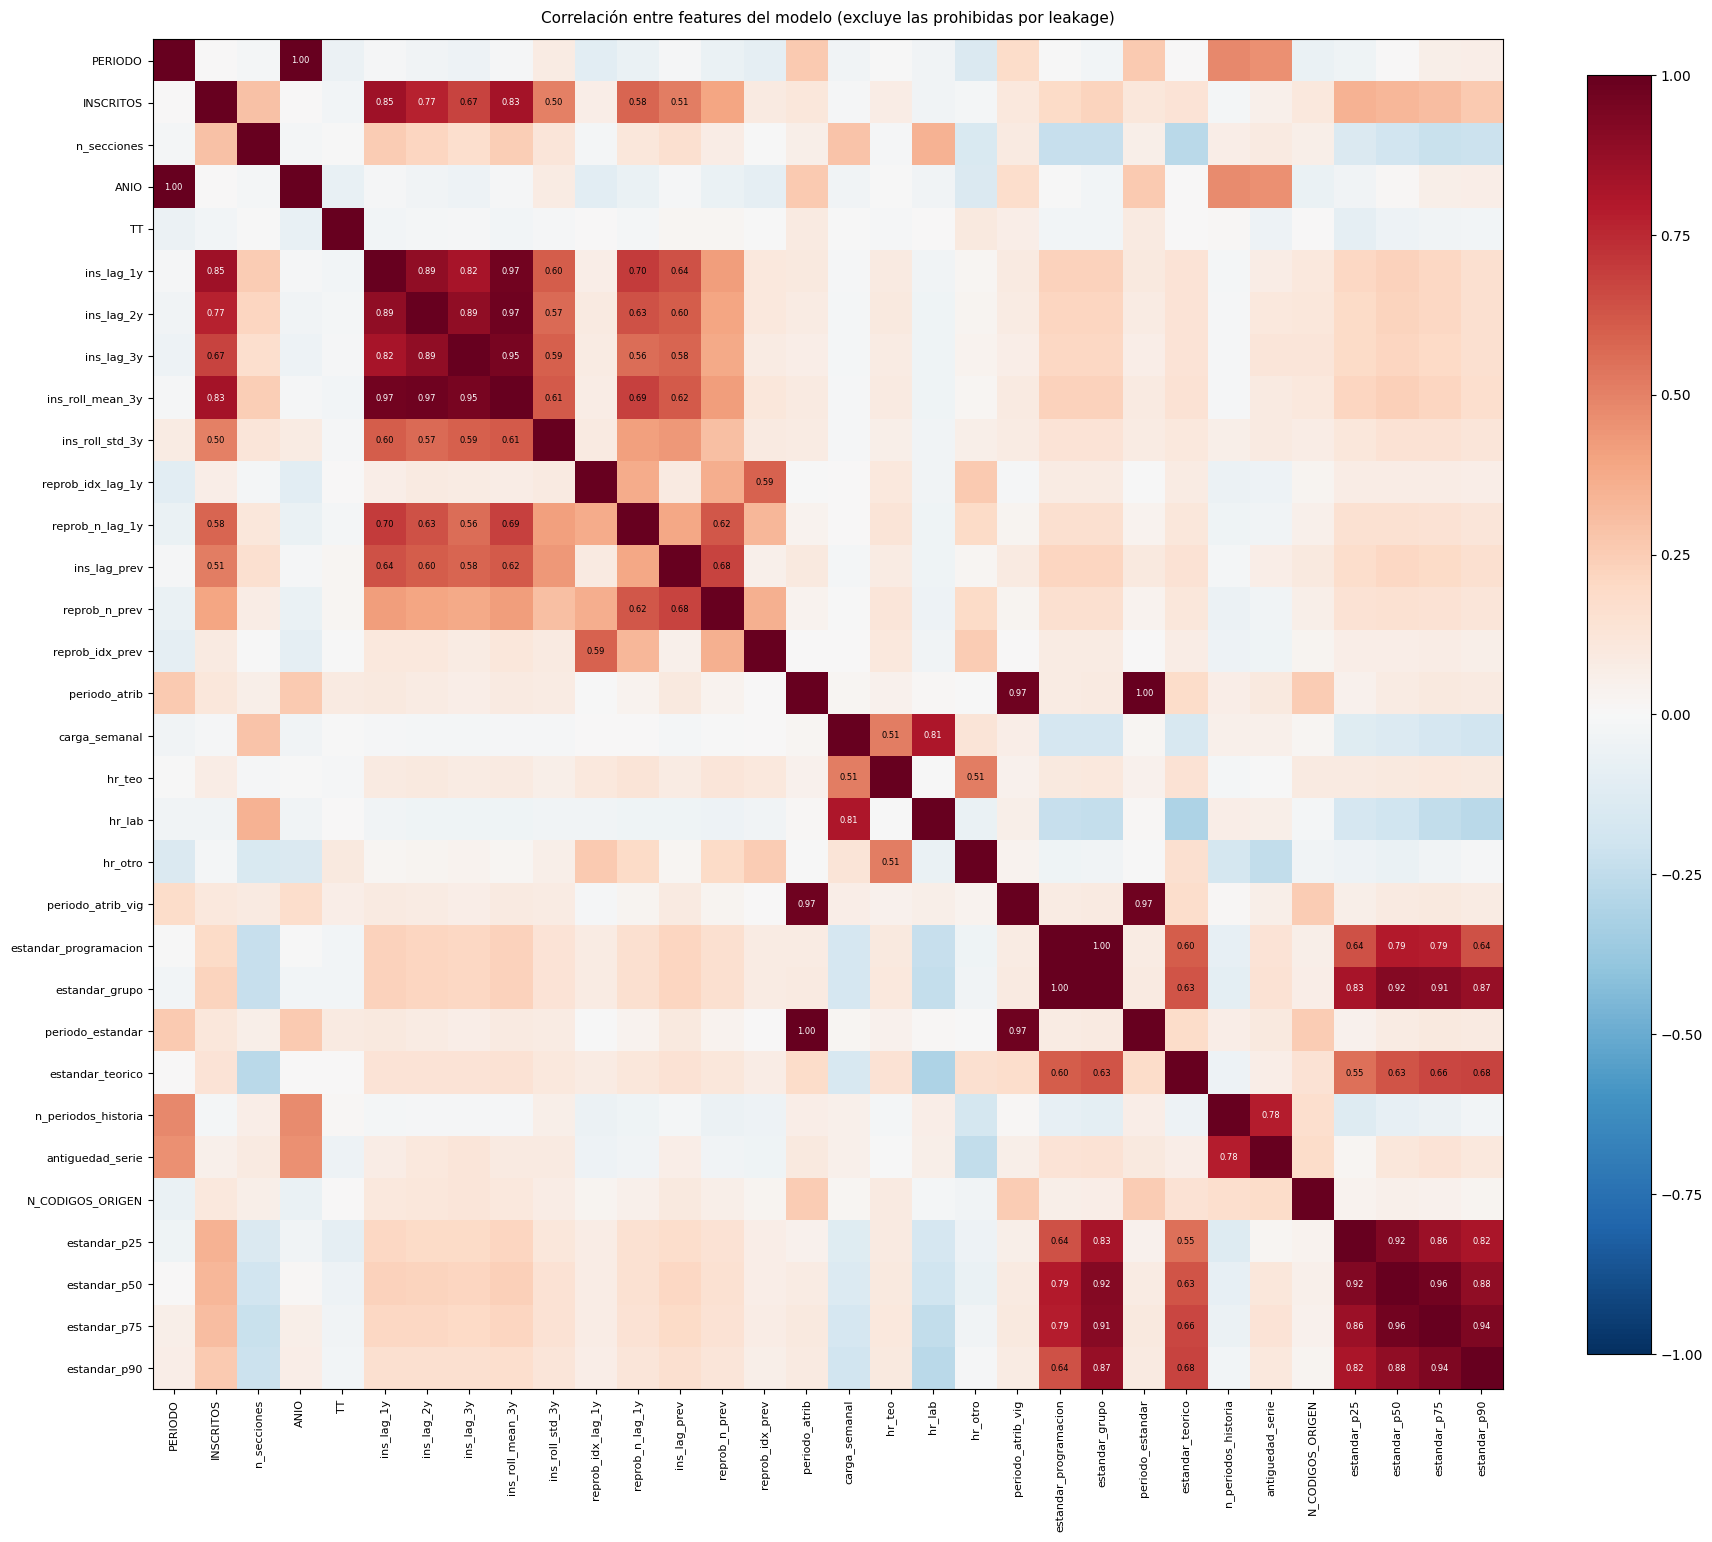


✔ Exportado: data/raw/AUDITORIA_FEATURES.csv


In [35]:
## ══════════════════════════════════════════════════════════════════════════════
## CELDA 28 · DIAGNÓSTICO · INGENIERÍA DE VARIABLES + HEATMAP DE CORRELACIÓN
## ══════════════════════════════════════════════════════════════════════════════
## QUÉ HACE : Audita las features de la sábana antes de entregarla al ML:
##            cobertura, columnas muertas, redundancia, correlación con el target
##            y un heatmap. Marca además las columnas PROHIBIDAS por anti-leakage.
## ENTRADA  : demanda
## SALIDA   : `auditoria_features` + AUDITORIA_FEATURES.csv + el heatmap en pantalla
## CLAVE    : Se audita sobre el DATASET DEL MODELO (TT 05/10/15/20/25), no sobre
##            la sábana completa: las coberturas cambian mucho entre uno y otro.
##            ⛔ Las columnas del período ACTUAL (reprobación, estándar observado)
##            viven en la sábana como referencia pero NO pueden entrar al modelo
##            (CONTEXTO §10). Aquí se listan para que su alta correlación con
##            INSCRITOS no se confunda con señal aprovechable: es leakage.
## ──────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

TT_MODELO_AUD = [5, 10, 15, 20, 25]
_dm = demanda[(demanda['PERIODO'] % 100).isin(TT_MODELO_AUD)]
_fuera = sorted(set(demanda['PERIODO'] % 100) - set(TT_MODELO_AUD))
print("═" * 78)
print(f"ALCANCE DE LA AUDITORÍA — solo TT {TT_MODELO_AUD}")
print("═" * 78)
print(f"  filas     : {len(demanda):,} -> {len(_dm):,}  ({len(_dm)/len(demanda):.1%})")
print(f"  inscritos : {demanda['INSCRITOS'].sum():,} -> {_dm['INSCRITOS'].sum():,}"
      f"  ({_dm['INSCRITOS'].sum()/demanda['INSCRITOS'].sum():.1%})")
print(f"  períodos  : {_dm['PERIODO'].nunique()}  |  columnas: {_dm.shape[1]}")
print(f"  TT excluidos ({len(_fuera)}): {_fuera}")
print("  (el TT 00 anual —postgrado— es el de mayor volumen entre los excluidos)")
if len(_dm) == len(demanda):
    print("  ⚠️ el filtro no descartó nada: revisar que la sábana traiga todos los TT.")
print()

# ── Familias de features y columnas prohibidas ──────────────────────────────
FAMILIA = {
    'LLAVE':       ['PERIODO', 'MATERIA', 'CURSO', 'COMPONENTE', 'CAMPUS', 'ASIGNATURA'],
    'TARGET':      ['INSCRITOS', 'n_secciones'],
    'CALENDARIO':  ['ANIO', 'TT'],
    'NIVEL':       ['periodo_nivel', 'cod_nivel_asig', 'desc_nivel_asig'],
    'LAGS':        ['ins_lag_1y', 'ins_lag_2y', 'ins_lag_3y', 'ins_roll_mean_3y',
                    'ins_roll_std_3y', 'ins_lag_prev'],
    'REPROB_LAG':  ['reprob_idx_lag_1y', 'reprob_n_lag_1y', 'reprob_n_prev', 'reprob_idx_prev'],
    'MALLA':       ['carga_semanal', 'cod_modo_programacion', 'hr_teo', 'hr_lab', 'hr_otro',
                    'departamento/form_general', 'vigente', 'atributos_imputados'],
    'ESTANDAR':    ['estandar_programacion', 'estandar_grupo', 'estandar_fuente',
                    'estandar_imputado', 'estandar_teorico', 'seccion_masiva',
                    'periodo_estandar'],
    'MADUREZ':     ['n_periodos_historia', 'antiguedad_serie', 'es_serie_nueva',
                    'sin_historia_estacional'],
    'HOMOLOGACION': ['REGLA', 'CODIGOS_ORIGEN', 'N_CODIGOS_ORIGEN'],
    'AUDITORIA':   ['periodo_atrib', 'tipo_match', 'periodo_atrib_vig', 'tipo_match_vig'],
}
PROHIBIDAS = ['n_aprobados', 'n_reprobados', 'n_registros', 'n_evaluados',
              'indice_reprobacion', 'tasa_reprobacion', 'estandar_observado',
              'ratio_ocupacion']   # del período actual -> leakage (CONTEXTO §10)

_fam = {c: f for f, cs in FAMILIA.items() for c in cs}
_filas = []
for _c in _dm.columns:
    _s = _dm[_c]
    _nu = int(_s.nunique(dropna=True))
    _filas.append({'columna': _c,
                   'familia': 'PROHIBIDA' if _c in PROHIBIDAS else _fam.get(_c, 'otra'),
                   'dtype': str(_s.dtype), 'cobertura': round(float(_s.notna().mean()), 4),
                   'nunique': _nu, 'constante': _nu <= 1,
                   'cobertura_baja': float(_s.notna().mean()) < 0.50})
auditoria_features = pd.DataFrame(_filas)

print("═" * 78); print("COBERTURA POR FAMILIA"); print("═" * 78)
print(auditoria_features.groupby('familia')
      .agg(columnas=('columna', 'size'), cobertura_media=('cobertura', 'mean'),
           constantes=('constante', 'sum'))
      .sort_values('cobertura_media').to_string())

print("\n" + "─" * 78); print("⚠️ BANDERAS"); print("─" * 78)
_cte = auditoria_features[auditoria_features['constante']]
print(f"  CONSTANTES (sin varianza, inútiles para el modelo): {len(_cte)}")
for _, _r in _cte.iterrows():
    print(f"     · {_r['columna']}  (familia {_r['familia']}, cobertura {_r['cobertura']:.1%})")
_baja = auditoria_features[auditoria_features['cobertura_baja'] & ~auditoria_features['constante']]
print(f"\n  COBERTURA < 50%: {len(_baja)}")
for _, _r in _baja.iterrows():
    print(f"     · {_r['columna']:26s} {_r['cobertura']:>6.1%}")

# ── Redundancia ─────────────────────────────────────────────────────────────
_num = [c for c in _dm.select_dtypes(include=[np.number]).columns
        if _dm[c].notna().sum() > 1000 and _dm[c].nunique() > 2]
_C = _dm[_num].corr(numeric_only=True)
_A = _C.abs().copy()
np.fill_diagonal(_A.values, 0)
_pares = (_A.stack().loc[lambda s: s > 0.95].reset_index())
_pares.columns = ['a', 'b', 'r']
_pares = _pares[_pares['a'] < _pares['b']].sort_values('r', ascending=False)
print(f"\n  PARES REDUNDANTES |r| > 0,95: {len(_pares)}")
for _, _r in _pares.iterrows():
    _mk = ' ⛔' if (_r['a'] in PROHIBIDAS or _r['b'] in PROHIBIDAS) else ''
    print(f"     · {_r['a']:24s} ~ {_r['b']:24s} r={_r['r']:.3f}{_mk}")

# ── Correlación con el target ───────────────────────────────────────────────
_ct = _dm[_num].corrwith(_dm['INSCRITOS']).drop('INSCRITOS', errors='ignore')
_ct = _ct.sort_values(key=abs, ascending=False)
print("\n" + "─" * 78); print("CORRELACIÓN CON INSCRITOS"); print("─" * 78)
print("  ⛔ = del período actual, PROHIBIDA como feature (su correlación es leakage)")
for _c, _v in _ct.head(14).items():
    print(f"     {'⛔' if _c in PROHIBIDAS else '  '} {_c:26s} {_v:>7.3f}")
print("\n  las más débiles (candidatas a descarte):")
for _c, _v in _ct.tail(6).items():
    print(f"        {_c:26s} {_v:>7.3f}")

# ── HEATMAP ─────────────────────────────────────────────────────────────────
_legit = [c for c in _num if c not in PROHIBIDAS]
_M = _dm[_legit].corr(numeric_only=True)
_fig, _ax = plt.subplots(figsize=(min(1 + 0.55 * len(_legit), 20),
                                  min(1 + 0.55 * len(_legit), 20)))
_im = _ax.imshow(_M.values, cmap='RdBu_r', vmin=-1, vmax=1)
_ax.set_xticks(range(len(_legit))); _ax.set_xticklabels(_legit, rotation=90, fontsize=8)
_ax.set_yticks(range(len(_legit))); _ax.set_yticklabels(_legit, fontsize=8)
_ax.set_title("Correlación entre features del modelo (excluye las prohibidas por leakage)",
              fontsize=11, pad=12)
for _i in range(len(_legit)):
    for _j in range(len(_legit)):
        _v = _M.values[_i, _j]
        if abs(_v) > 0.5 and _i != _j:
            _ax.text(_j, _i, f"{_v:.2f}", ha='center', va='center', fontsize=6,
                     color='white' if abs(_v) > 0.75 else 'black')
_fig.colorbar(_im, ax=_ax, shrink=0.7)
plt.tight_layout(); plt.show()

_out = f'{CARPETA}/AUDITORIA_FEATURES.csv'
auditoria_features.to_csv(_out, sep=';', encoding='utf-8-sig', index=False, decimal=',')
print(f"\n✔ Exportado: {_out}")
